# Analyse descriptive (exploratoire, hors livrable officiel)

**Origine : Laurice** — objectif : calculer des indicateurs (fréquence, coût moyen, volumes) à partir de la base fiabilisée, observer leur évolution selon les variables du portefeuille, pour décider ensuite ce qui mérite d'entrer dans le reporting final (et à quel niveau de détail).

Ce notebook n'est pas un livrable du cahier des charges (section 3 : exclusions). Il part de `df_base_fiabilisee` (construite comme dans `data_analysis.ipynb`) et crée une base dédiée `df_analyse` (copie enrichie de colonnes de classes pour les variables continues).

Du plus global (KPIs du portefeuille) au plus détaillé (analyses croisées 2 à 2), conformément à la demande.

## Importation

In [1]:
import itertools
import os
import re
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from src.jointure import isoler_orphelins, joindre_contrats_sinistres
from src.telechargement import (
    RACINE_PROJET,
    charger_parametres,
    telecharger_reference_geographique,
    telecharger_sources,
)

## Paramètres

In [2]:
os.environ["JAVA_HOME"] = os.path.join(sys.prefix, "Library")
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("analyse_descriptive")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)

parametres = charger_parametres()

# Nombre de classes par variable continue. Un seul endroit a modifier pour
# ajuster la finesse de chaque analyse en classes.
# Origine : Laurice -- VehAge et DrivAge passent a 10 classes (au lieu de 5)
# pour mieux voir la forme en cloche de VehAge et l'effet des tres jeunes
# conducteurs sur DrivAge. BonusMalus et Density restent a 5.
NB_CLASSES_PAR_VARIABLE = {"VehAge": 10, "DrivAge": 10}
NB_CLASSES_DEFAUT = 5

## Chargement et jointure (identique à `data_analysis.ipynb`)

On repart de zéro (téléchargement + jointure) plutôt que de dépendre de l'ordre d'exécution d'un autre notebook : ce notebook reste reproductible seul (ENF2).

In [3]:
telecharger_sources(parametres)
chemin_contrats = RACINE_PROJET / parametres["sources"]["contrats"]["fichier"]
chemin_sinistres = RACINE_PROJET / parametres["sources"]["sinistres"]["fichier"]
df_contrats = spark.read.csv(str(chemin_contrats), header=True, inferSchema=True)
df_sinistres = spark.read.csv(str(chemin_sinistres), header=True, inferSchema=True)
df_contrats = df_contrats.withColumn("IDpol", F.col("IDpol").cast("long").cast("string"))
df_sinistres = df_sinistres.withColumn("IDpol", F.col("IDpol").cast("long").cast("string"))

cle = parametres["jointure"]["cle"]
df_base_fiabilisee = joindre_contrats_sinistres(df_contrats, df_sinistres, cle)

## Création de `df_analyse` : classes pour les variables continues

**Origine : Laurice** — demande de regrouper les variables continues (`VehAge`, `DrivAge`, `BonusMalus`, `Density`) en classes lisibles plutôt que de garder des graphiques avec une valeur par point.

**Origine : IA** — choix technique : classes par **quantiles** (bornes calculées avec `approxQuantile`, scalable en Spark) plutôt que des classes de largeur égale. Avec des variables aussi asymétriques que `Density` (de 1 à 27000), des classes de largeur égale donneraient une classe géante et plusieurs classes quasi vides. Les quantiles donnent des classes avec un nombre comparable de contrats, donc des fréquences plus fiables à comparer entre elles. Laurice peut changer `NB_CLASSES_PAR_VARIABLE` ci-dessus (VehAge et DrivAge sont passés à 10 classes à sa demande), ou me dire de passer à des classes de largeur égale si elle préfère.

**Origine : IA** — remarque technique : `BonusMalus` donne naturellement moins de classes que demandé (3 au lieu de 5), car 56.7% des contrats sont au plancher légal (50) : les quantiles se chevauchent et sont dédupliqués (`sorted(set(...))`). Ce n'est pas un bug, c'est la conséquence logique d'une variable très concentrée sur une valeur.

In [4]:
ordres_classes = {}  # colonne -> liste des etiquettes, dans l'ordre croissant


def ajouter_classe(df, colonne, nb_classes=NB_CLASSES_DEFAUT):
    """Ajoute une colonne classe_{colonne} (quantiles, bornes lisibles) et
    retient l'ordre croissant des etiquettes dans ordres_classes, car ce
    n'est pas un ordre alphabetique ("< 32" doit venir avant "[32, 40[",
    qui doit venir avant ">= 57").
    """
    quantiles = [i / nb_classes for i in range(nb_classes + 1)]
    bornes = sorted(set(df.approxQuantile(colonne, quantiles, 0.01)))

    def etiquette(i):
        if i == 0:
            return f"< {bornes[1]:.0f}"
        if i == len(bornes) - 2:
            return f">= {bornes[i]:.0f}"
        return f"[{bornes[i]:.0f}, {bornes[i+1]:.0f}["

    etiquettes = [etiquette(i) for i in range(len(bornes) - 1)]
    ordres_classes[f"classe_{colonne}"] = etiquettes

    expr = F.lit(etiquettes[-1])
    for i in range(len(bornes) - 2, -1, -1):
        expr = F.when(F.col(colonne) < bornes[i + 1], F.lit(etiquettes[i])).otherwise(expr)
    return df.withColumn(f"classe_{colonne}", expr)


df_analyse = df_base_fiabilisee
for colonne in ("VehAge", "DrivAge", "BonusMalus", "Density"):
    nb_classes = NB_CLASSES_PAR_VARIABLE.get(colonne, NB_CLASSES_DEFAUT)
    df_analyse = ajouter_classe(df_analyse, colonne, nb_classes)

df_analyse = df_analyse.cache()
df_analyse.count()  # materialise le cache

678013

### Ordre des modalités

**Origine : Laurice** — remarque : les modalités doivent rester dans un ordre logique, pas alphabétique (ex: la classe `>= 57` ne doit pas passer avant `[32, 40[`, et `VehBrand` "B10" ne doit pas passer avant "B2"). Pour les variables en classes, on réutilise l'ordre retenu dans `ordres_classes`. Pour les autres (ex: `VehBrand`), un **tri naturel** (qui compare les nombres embarqués dans le texte, pas caractère par caractère) suffit. Que les modalités suivent un ordre logique ou non reste à vérifier au cas par cas (ex: `Region`, `VehGas`) : dis-moi si l'un de ces tris reste faux quelque part.

In [5]:
def cle_tri_naturel(valeur):
    """'B2' avant 'B10' : le tri alphabetique standard ferait l'inverse
    car il compare caractere par caractere ('1' < '2'). On remplace chaque
    nombre par sa version calee a gauche par des zeros ("2" -> "0000000002",
    "10" -> "0000000010") pour qu'un tri alphabetique standard donne alors
    le bon resultat.
    """
    return re.sub(r"\d+", lambda m: m.group().zfill(10), str(valeur))


def ordre_modalites(valeurs, variable):
    """Liste ordonnee des modalites presentes dans `valeurs` pour `variable` :
    ordre des classes si c'est une variable classee, sinon tri naturel.
    """
    presentes = set(valeurs)
    if variable in ordres_classes:
        return [v for v in ordres_classes[variable] if v in presentes]
    return sorted(presentes, key=cle_tri_naturel)

# A. Indicateurs globaux du portefeuille

Le niveau le plus global, avant toute décomposition par variable.

In [6]:
kpis = (
    df_analyse.agg(
        F.count("*").alias("nb_contrats"),
        F.sum("Exposure").alias("exposition_totale"),
        F.sum("ClaimNb").alias("claimnb_total"),
        F.sum("nb_sinistres_reel").alias("nb_sinistres_reel_total"),
        F.sum("montant_total_sinistres").alias("charge_totale"),
    )
    .toPandas()
    .iloc[0]
)
kpis["frequence_globale"] = kpis["nb_sinistres_reel_total"] / kpis["exposition_totale"]
kpis["cout_moyen_global"] = kpis["charge_totale"] / kpis["nb_sinistres_reel_total"]
# Prime pure (Origine : IA) : indicateur de synthese frequence x cout moyen,
# standard en tarification, utile pour comparer des segments en un seul chiffre.
kpis["prime_pure_globale"] = kpis["frequence_globale"] * kpis["cout_moyen_global"]
kpis.to_frame(name="valeur")

,valeur
nb_contrats,6.780130e+05
exposition_totale,3.584994e+05
claimnb_total,3.610200e+04
nb_sinistres_reel_total,2.644400e+04
charge_totale,5.990922e+07
frequence_globale,7.376302e-02
cout_moyen_global,2.265513e+03
prime_pure_globale,1.671110e+02


**Origine : Laurice**

- Ceci ne sert à rien : frequence_globale	7.376302e-02
cout_moyen_global	2.265513e+03
prime_pure_globale	1.671110e+02
- Les autres ca va et peut etre mis dans le reporting html interactif

### Sinistres réellement déclarés (`ClaimNb`) vs sinistres à coût connu (`nb_sinistres_reel`)

**Origine : Laurice**

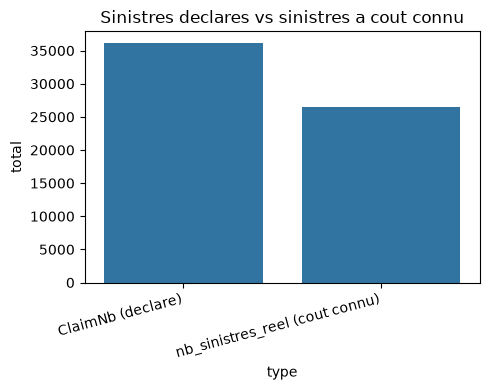

In [7]:
comparaison_declare_connu = pd.DataFrame({
    "type": ["ClaimNb (declare)", "nb_sinistres_reel (cout connu)"],
    "total": [kpis["claimnb_total"], kpis["nb_sinistres_reel_total"]],
})
plt.figure(figsize=(5, 4))
sns.barplot(data=comparaison_declare_connu, x="type", y="total")
plt.title("Sinistres declares vs sinistres a cout connu")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Origine : Laurice**

- Dans reporting aussi mais pas le plus important

# B. Fréquence par variable (univariée)

**Origine : Laurice** — fréquence = `nb_sinistres_reel / Exposure`, avec l'exposition totale affichée en barres (volume du groupe) et la fréquence en ligne (taux). Permet de voir si une variation de fréquence s'appuie sur un groupe important ou sur quelques contrats seulement.

9 variables demandées : `Area`, `VehPower`, `classe_VehAge`, `classe_DrivAge`, `classe_BonusMalus`, `VehBrand`, `VehGas`, `classe_Density`, `Region`. Regarde chaque graphique et dis-moi lesquels éliminer (non pertinent / illisible).

In [8]:
variables_univariees = [
    "Area", "VehPower", "classe_VehAge", "classe_DrivAge",
    "classe_BonusMalus", "VehBrand", "VehGas", "classe_Density", "Region",
]


def tableau_univarie(df, variable):
    agrege = (
        df.groupBy(variable)
        .agg(
            F.count("*").alias("nb_contrats"),
            F.sum("Exposure").alias("exposition_totale"),
            F.sum("nb_sinistres_reel").alias("nb_sinistres_reel"),
            F.sum("montant_total_sinistres").alias("montant_total_sinistres"),
        )
        .toPandas()
    )
    ordre = ordre_modalites(agrege[variable], variable)
    agrege[variable] = pd.Categorical(agrege[variable], categories=ordre, ordered=True)
    agrege = agrege.sort_values(variable)
    agrege["frequence"] = agrege["nb_sinistres_reel"] / agrege["exposition_totale"]
    # cout_moyen = NaN si aucun sinistre dans le groupe (division par 0 evitee).
    # np.nan et pas pd.NA : seaborn (heatmap/lineplot) ne sait pas lire pd.NA.
    agrege["cout_moyen"] = agrege["montant_total_sinistres"] / agrege["nb_sinistres_reel"].replace(0, np.nan)
    agrege["prime_pure"] = agrege["frequence"] * agrege["cout_moyen"]
    return agrege


def graphe_bar_ligne(tableau, variable, colonne_ligne, titre_ligne, couleur="crimson"):
    """Barres = exposition totale (volume). Ligne = l'indicateur demande
    (frequence, cout_moyen ou prime_pure), sur un axe secondaire.
    """
    fig, ax1 = plt.subplots(figsize=(8, 4))
    sns.barplot(data=tableau, x=variable, y="exposition_totale", ax=ax1, color="lightgray")
    ax1.set_ylabel("Exposition totale")
    ax2 = ax1.twinx()
    sns.lineplot(data=tableau, x=variable, y=colonne_ligne, ax=ax2, color=couleur, marker="o")
    ax2.set_ylabel(titre_ligne)
    plt.title(f"{titre_ligne} par {variable}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

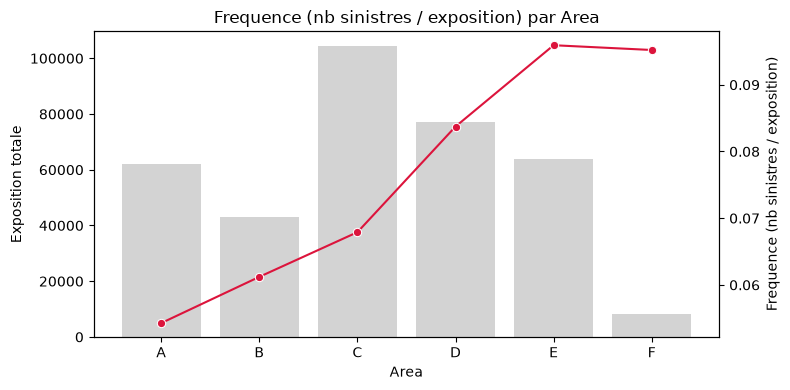

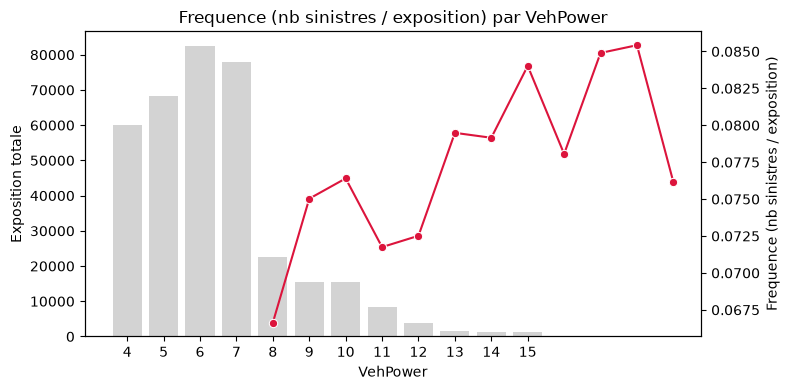

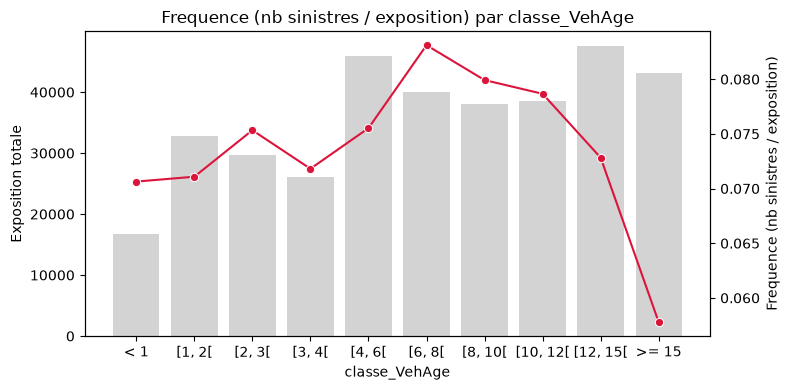

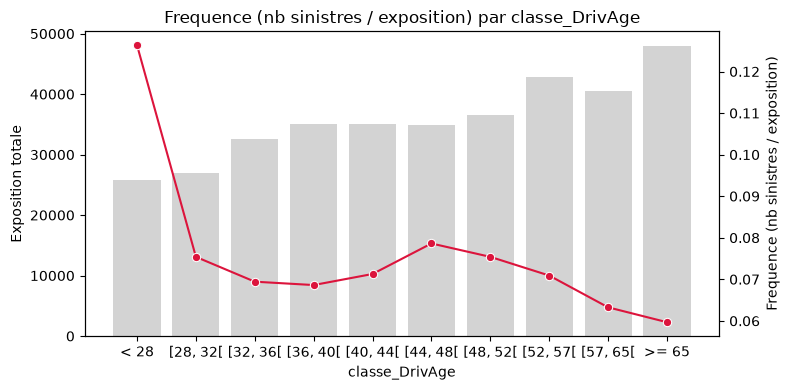

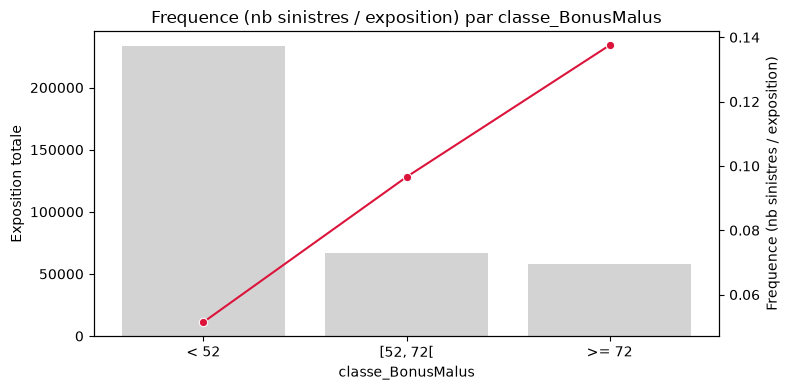

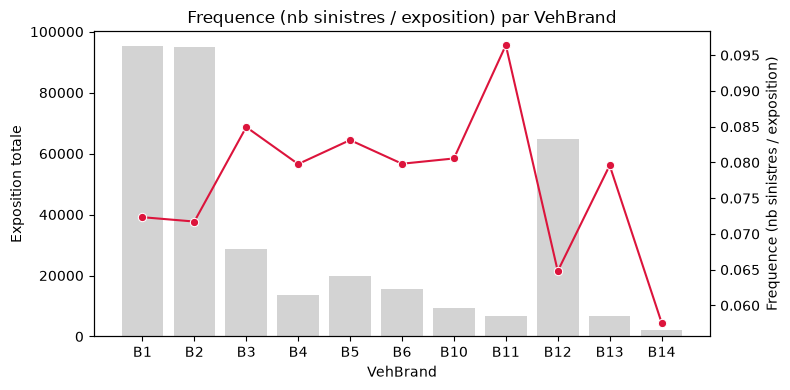

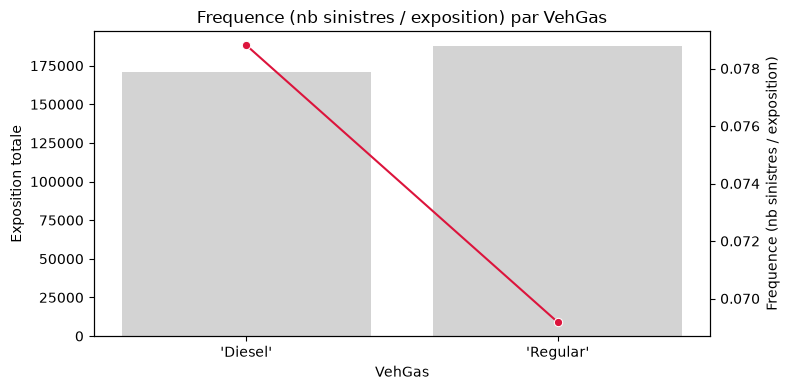

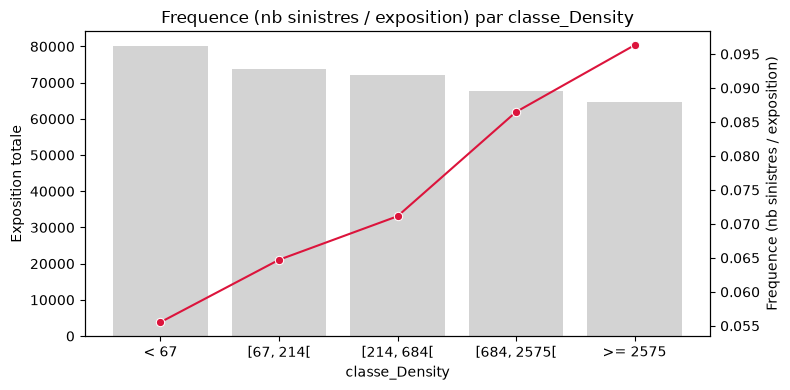

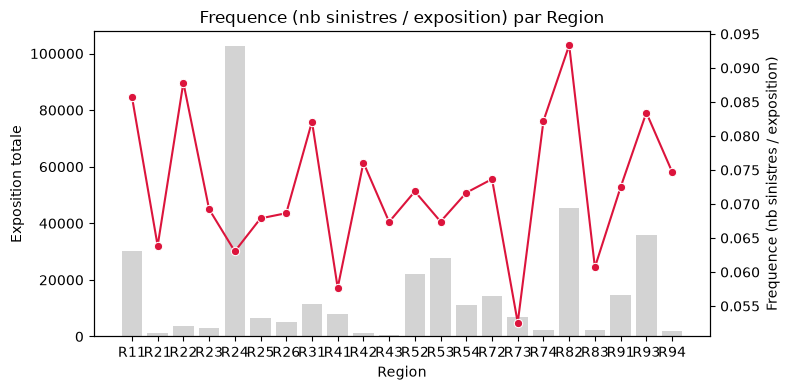

In [9]:
for variable in variables_univariees:
    tableau = tableau_univarie(df_analyse, variable)
    graphe_bar_ligne(tableau, variable, "frequence", "Frequence (nb sinistres / exposition)")

**Origine : Laurice**

## Interprétation Technique
- On remarque que La frequence est croissant avec la zone de très rural à très urbain (si A et F correspondent bien à ca)
- La frequence d'un sinistre Auto ne depend pas forcément de la puissance du vehicule.-La puissance d'un vehicule peut etre important mais pas seule
- La freq croit avec l'âge du vehicule de 0-12 puis decroit 
- Le découpage en 5 classe de l'age du conducteur n'est pas très claire et ne permet pas de donner une interprétation claire (globalement decroissant mais est ce le cas coté metier réellement et pourquoi ?)
- La marque du vehicule aussi seule e suffit pas à voir de tendance 
- Véhicule diesel on plus de sinistres que regular (variable indirect)
- Fréquence croit avec la Densité (On vera que Area et Densité explique la même chose, la taille de la population)
- Certaines regions ont des frequences de sinistres élévées


## Interprétation opérationnel (vu directement dans reporting)

- un assuré en zone F est donc plus risqué et recevra un prime plus elevé , cest profile sont a surveiller aussi car il y'en a E et Fafin de ne pas en avoir trop
- Pas d'idée opérationnel pour cette var
- Quel peut etre l'explication metier volet operationnel de cette tendance sur la variable âge du véhicule
- Vehicul diesel sont plus frequemment accidenté juste parceque on dure plus sur la route vu qu'il est generlement payé lors des trajets long
- Les assuré dans des zones urbaines ont beacoup plus d'accident du a la forte circulation
- Regions a surveiller, surement tres urbaines et population dense

## Avis IA sur la fréquence (vérifié sur les vraies données)

**Origine : IA** — j'ai recalculé chaque observation sur les 678013 contrats pour la confirmer ou la nuancer, plutôt que de la commenter de tête.

- **Area E/F** : fréquences quasi identiques (E=0.0959, F=0.0952, écart de 0.0007) — regroupement confirmé, statistiquement justifié.
- **VehPower** : je nuancerais "pas de tendance" — il y a une légère tendance croissante (0.067 à puissance 4, jusqu'à 0.085 à puissance 13) mais bruitée (la puissance 15 retombe). Probablement un effet réel mais faible, noyé par le bruit sur les petits groupes (VehPower 13/14/15 ont très peu de contrats).
- **VehAge en cloche** : confirmé numériquement (0.071→0.074→0.079→0.079 puis chute à 0.066 pour >= 12 ans). Le passage à 10 classes va permettre de voir si la chute est progressive ou un vrai seuil.
- **DrivAge, effet jeune** : très marqué — les moins de 32 ans ont une fréquence de 0.100, soit le double de la tranche 50-57 ans (0.061). C'est l'effet le plus fort observé sur toutes les variables univariées.
- **BonusMalus croissant** : confirmé (0.051→0.097→0.138), mais attention — le bonus-malus encode déjà l'historique de sinistres du conducteur (cf. section sur le bonus-malus plus haut dans `data_analysis.ipynb`). Cette corrélation est donc en partie mécanique (une sorte de fuite d'information), pas une découverte indépendante.
- **VehBrand, Diesel, Density, Region** : tes observations sont toutes confirmées par les chiffres. Pour Diesel, j'ajouterais une explication alternative à la tienne : les diesels sont souvent achetés justement pour les longs trajets (ce qui est cohérent avec plus d'occasions d'accrocher), mais ça reste une hypothèse parmi d'autres, non testable avec ces seules données.

# C. Coût moyen par variable (univariée)

**Origine : Laurice** — même analyse que la fréquence, mais pour le coût moyen (sévérité). Calculé uniquement sur les groupes ayant au moins un sinistre (sinon division par 0 : décision prise avec Laurice).

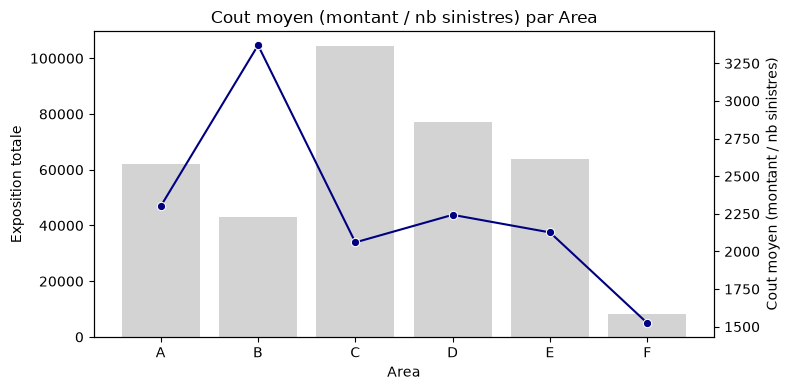

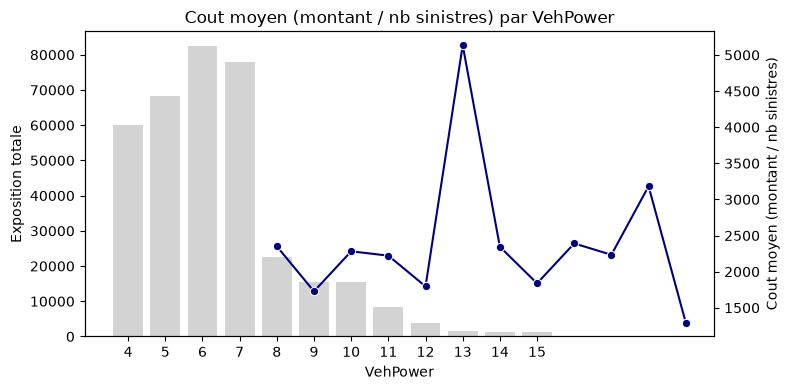

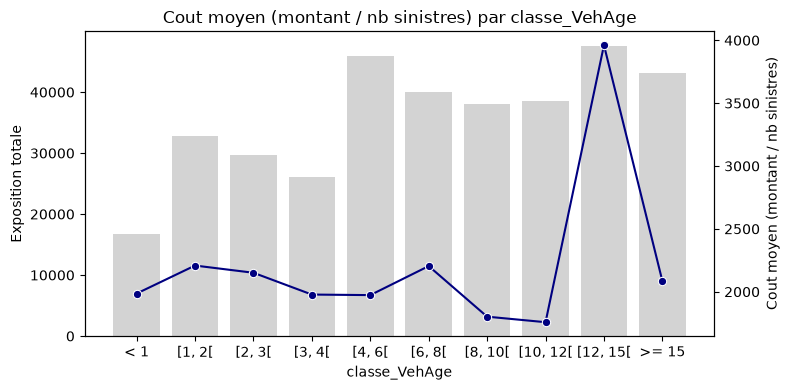

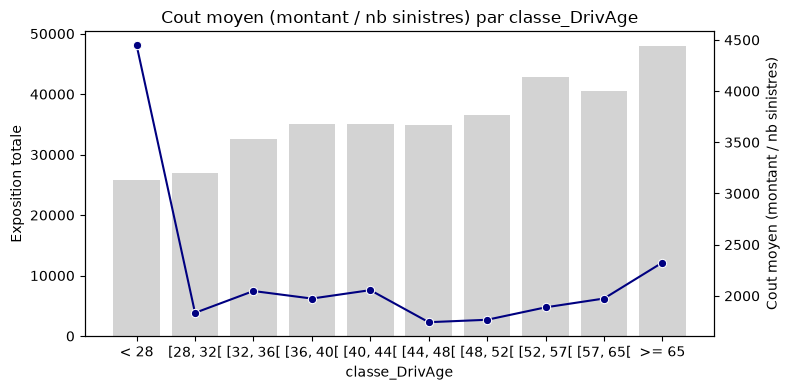

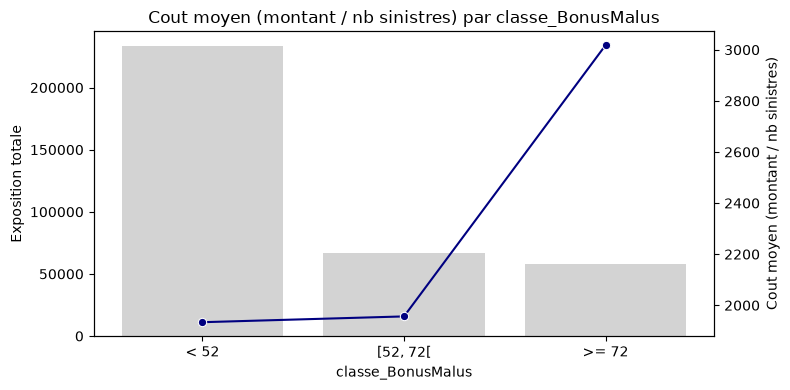

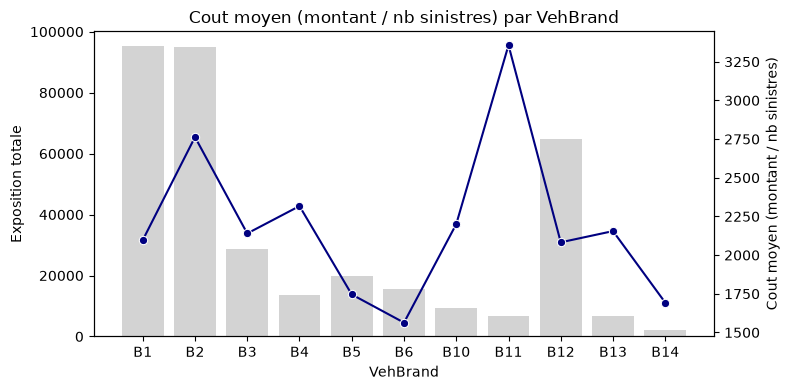

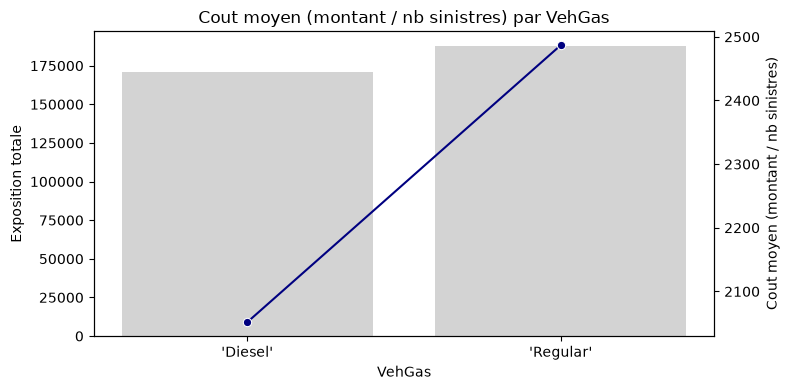

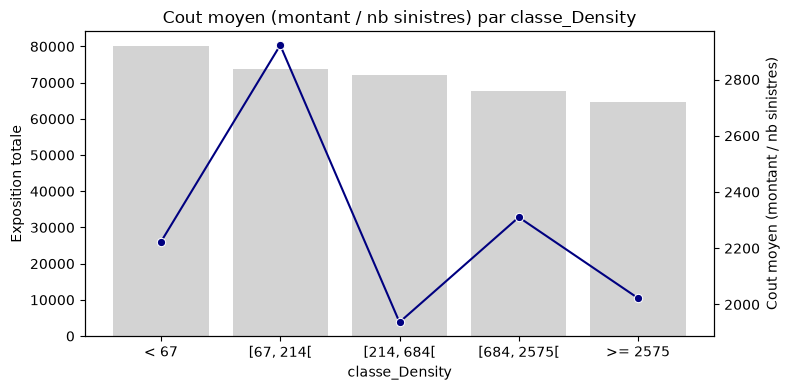

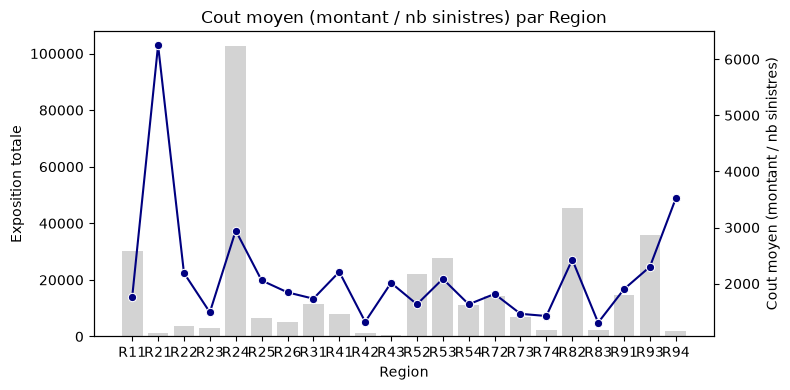

In [10]:
for variable in variables_univariees:
    tableau = tableau_univarie(df_analyse, variable).dropna(subset=["cout_moyen"])
    graphe_bar_ligne(tableau, variable, "cout_moyen", "Cout moyen (montant / nb sinistres)", couleur="navy")

**Origine : Laurice**

## Interprétation (coût moyen)
- La charge décroît un peu à partir de B (Area)
- VehPower : pas de tendance
- Âge du véhicule : même remarque qu'en fréquence (forme en cloche)
- Âge du conducteur : même remarque
- BonusMalus : deux classes semblent suffire ici (plutôt que 3)
- VehBrand : pas de tendance
- VehGas : tendance inverse de la fréquence
- Density : pas de tendance
- Region : pas de tendance

## Avis IA sur le coût moyen (vérifié sur les vraies données)

**Origine : IA** — même démarche : chaque point est recalculé sur les vraies données avant de le confirmer ou le nuancer.

- **Area** : confirmé partiellement — ça monte de A (2301€) à B (3370€, le pic), puis redescend globalement jusqu'à F (1524€), mais pas de façon parfaitement monotone (D remonte légèrement par rapport à C). "Décroît à partir de B" est une bonne synthèse visuelle.
- **VehPower, pas de tendance** : confirmé, et à signaler — **VehPower=9 est un outlier** (coût moyen 5135€, plus du double des autres classes), probablement 1-2 sinistres très chers sur un petit groupe (1220 sinistres). À ne pas interpréter comme un vrai effet métier sans vérifier ces sinistres individuellement.
- **BonusMalus, 2 classes suffisent** : confirmé numériquement — les deux premières classes ont un coût quasi identique (<52 : 1934€, [52,72[ : 1956€), alors que la 3e explose (>=72 : 3018€). Fusionner les deux premières rendrait le graphique plus lisible sans perdre d'information (elles ne sont pas statistiquement distinguables ici).
- **VehGas, tendance inverse** : confirmé et c'est un point important à souligner dans le reporting — le Diesel est plus **fréquent** (0.079 vs 0.069) mais moins **cher en moyenne** (2052€ vs 2487€). Les deux effets se compensent partiellement : c'est la **prime pure** (fréquence × coût moyen, section G) qui donnera le vrai écart net entre les deux carburants, pas la fréquence seule.
- **Region, pas de tendance** : confirmé, mais à nuancer — R21 a un coût moyen de 6250€ (3x les autres régions), sur seulement 77 sinistres. C'est très probablement du bruit statistique (petit échantillon, un ou deux sinistres chers suffisent à faire exploser une moyenne), pas un vrai signal régional. Pour ce genre de variable à fort volume de modalités et faible effectif par groupe, le coût moyen brut est fragile — une médiane ou un intervalle de confiance serait plus robuste si ce point devait entrer dans le reporting final.

# D. Fréquence croisée (toutes les combinaisons 2 à 2)

**Origine : Laurice** — fréquence par croisement de 2 variables (ex: âge du conducteur x âge du véhicule), en heatmap. Toutes les combinaisons possibles parmi les 9 variables ci-dessus sont générées (36 au total) : regarde-les et dis-moi lesquelles éliminer.

**Origine : IA** — suite à ta remarque sur la difficulté de lire les heatmaps : à partir de maintenant, les paires où les deux variables ont peu de modalités (≤ 6, ex: Area, VehPower, les classes, VehGas) sont affichées en **graphique d'interaction** (une ligne par modalité) plutôt qu'en heatmap — on voit directement la forme des courbes et si elles se croisent. Les paires à forte cardinalité (VehBrand, Region) restent en heatmap, avec les valeurs annotées quand la grille n'est pas trop grande.

In [11]:
# Origine : IA -- en dessous de ce seuil de modalites sur les deux axes,
# un graphique d'interaction (une ligne par modalite) est plus lisible
# qu'une heatmap : on voit directement la forme de la courbe et les
# croisements entre modalites, ce qu'une echelle de couleur masque
# facilement (surtout avec une valeur outlier qui ecrase le reste de
# l'echelle). Au-dela, trop de lignes rendraient le graphique illisible,
# donc on garde la heatmap (avec annotations si la grille reste petite).
SEUIL_CARDINALITE_INTERACTION = 6


def tableau_croise(df, var1, var2):
    agrege = (
        df.groupBy(var1, var2)
        .agg(
            F.sum("Exposure").alias("exposition_totale"),
            F.sum("nb_sinistres_reel").alias("nb_sinistres_reel"),
            F.sum("montant_total_sinistres").alias("montant_total_sinistres"),
        )
        .toPandas()
    )
    agrege["frequence"] = agrege["nb_sinistres_reel"] / agrege["exposition_totale"]
    agrege["cout_moyen"] = agrege["montant_total_sinistres"] / agrege["nb_sinistres_reel"].replace(0, np.nan)
    return agrege


def graphe_interaction(pivot, var1, var2, titre):
    """Une ligne par modalite de var2, x = var1 (ordonne). Alternative a
    la heatmap quand les deux variables ont peu de modalites.
    """
    plt.figure(figsize=(7, 4))
    for modalite in pivot.columns:
        plt.plot(pivot.index.astype(str), pivot[modalite], marker="o", label=str(modalite))
    plt.title(f"{titre} : {var1} x {var2}")
    plt.xlabel(var1)
    plt.ylabel(titre)
    plt.xticks(rotation=45, ha="right")
    plt.legend(title=var2, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def graphe_croise(df, var1, var2, valeur, titre, cmap):
    agrege = tableau_croise(df, var1, var2)
    pivot = agrege.pivot(index=var1, columns=var2, values=valeur)
    # reindex : meme logique d'ordre que pour les graphiques univaries
    # (sinon pivot() trie les lignes/colonnes par ordre alphabetique).
    pivot = pivot.reindex(
        index=ordre_modalites(pivot.index, var1),
        columns=ordre_modalites(pivot.columns, var2),
    )
    if pivot.shape[0] <= SEUIL_CARDINALITE_INTERACTION and pivot.shape[1] <= SEUIL_CARDINALITE_INTERACTION:
        graphe_interaction(pivot, var1, var2, titre)
        return
    plt.figure(figsize=(8, 5))
    # annoter les valeurs seulement si la grille reste lisible (pas trop de cellules)
    annoter = pivot.size <= 60
    fmt = ".3f" if valeur == "frequence" else ".0f"
    sns.heatmap(pivot, cmap=cmap, annot=annoter, fmt=fmt)
    plt.title(f"{titre} : {var1} x {var2}")
    plt.tight_layout()
    plt.show()

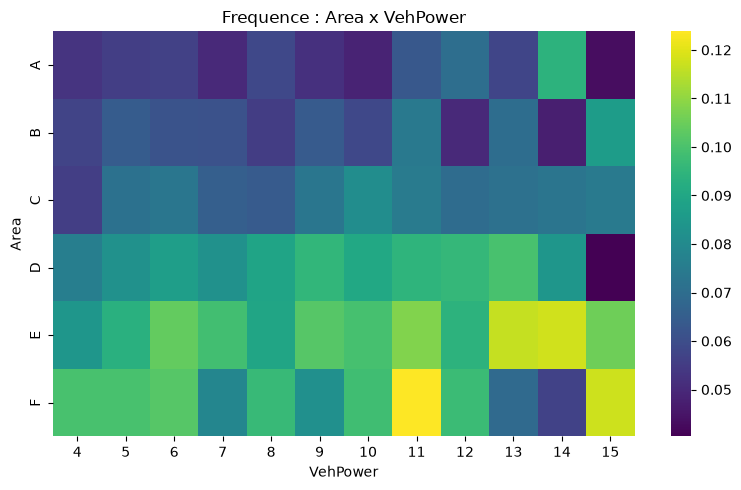

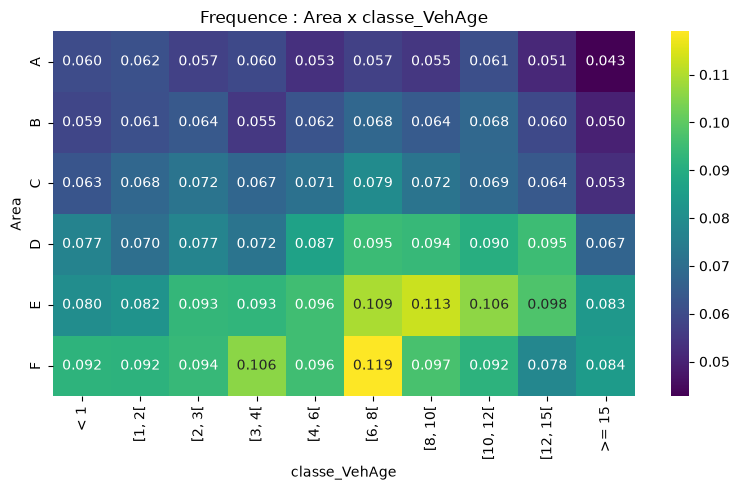

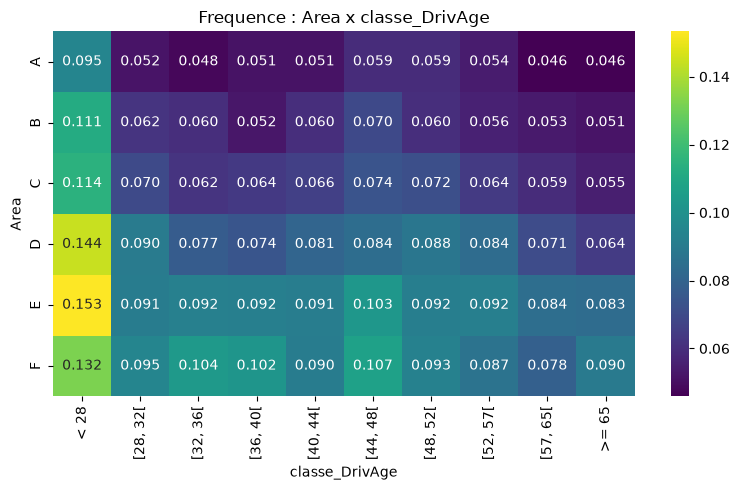

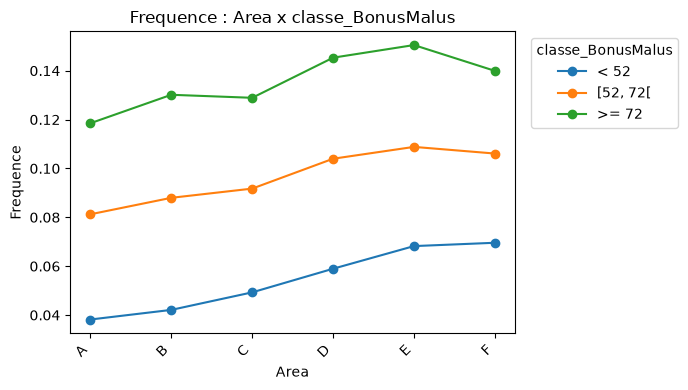

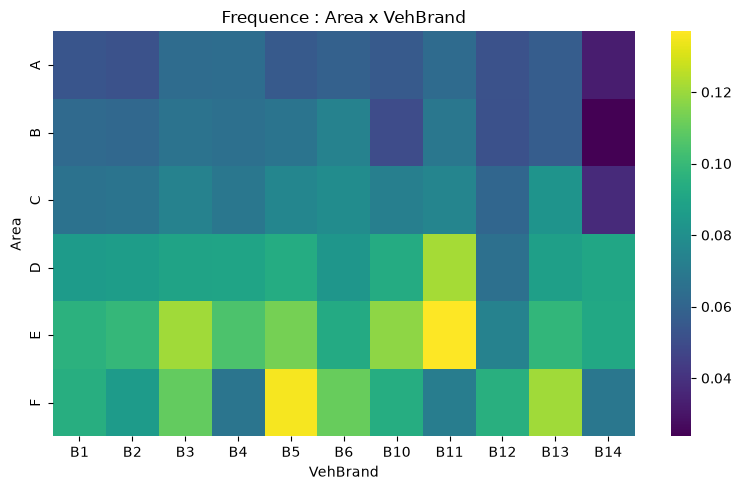

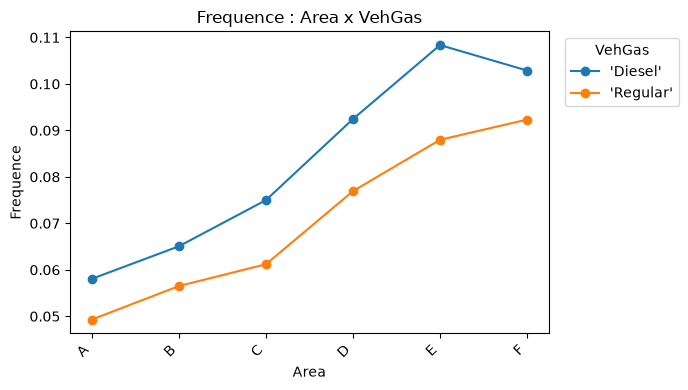

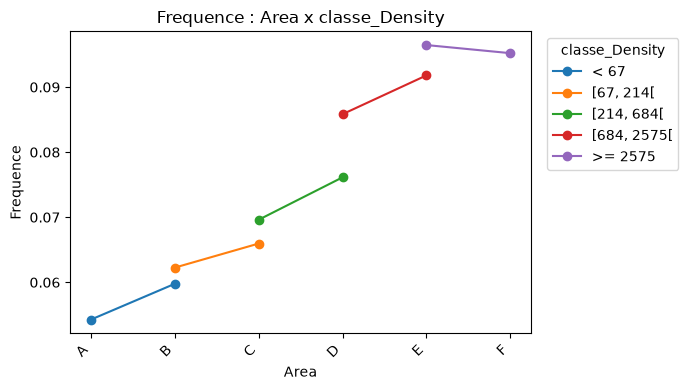

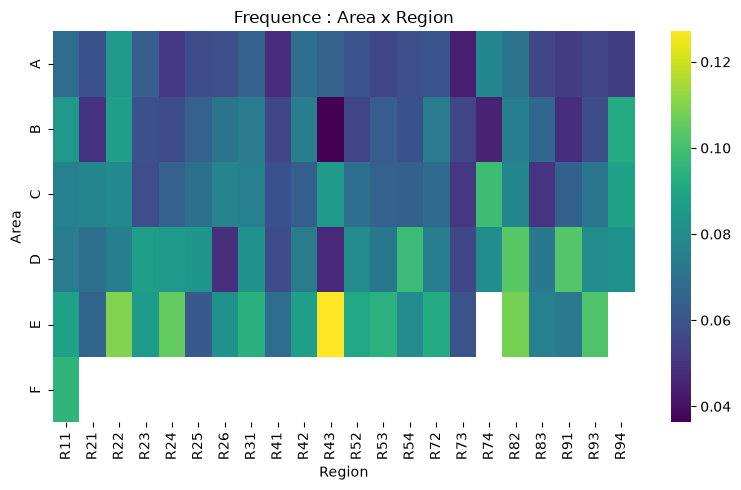

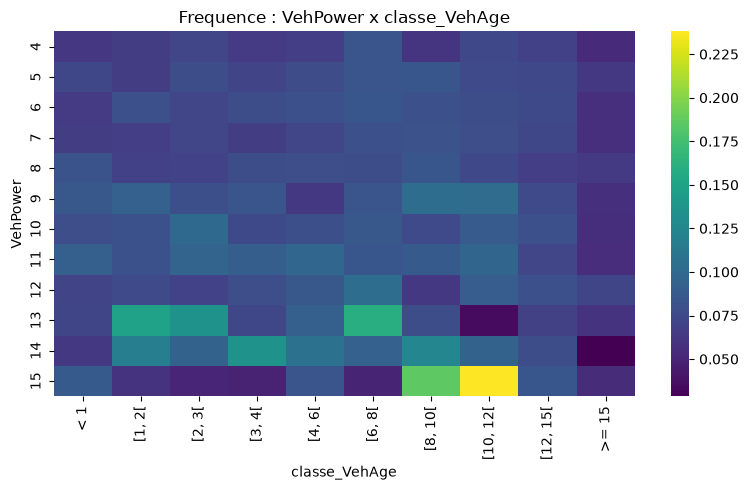

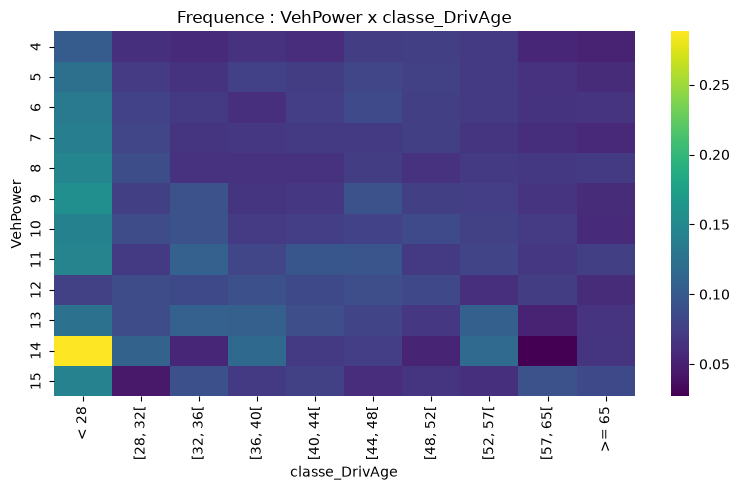

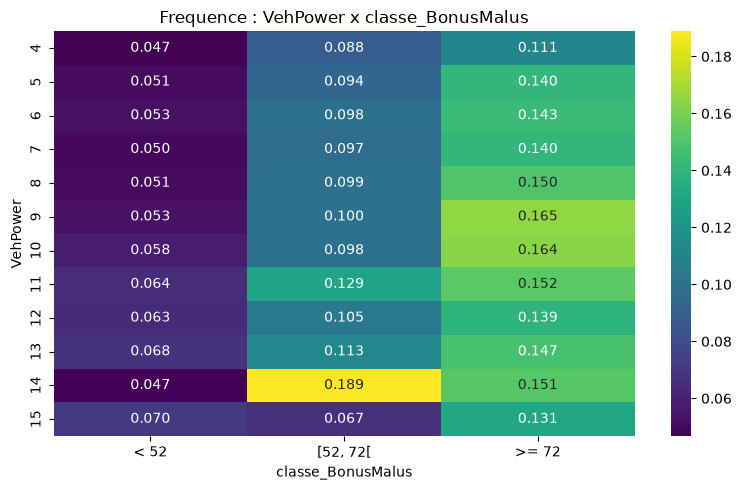

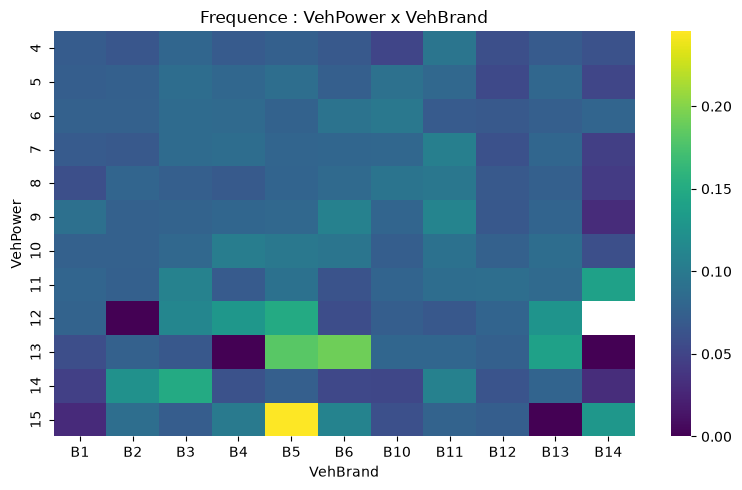

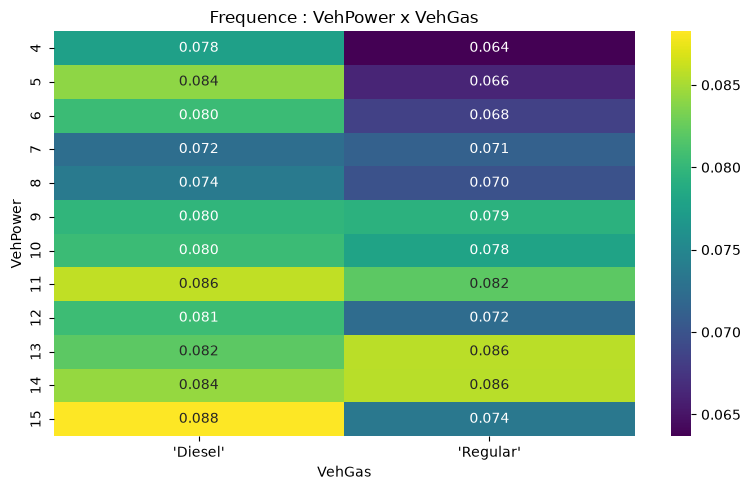

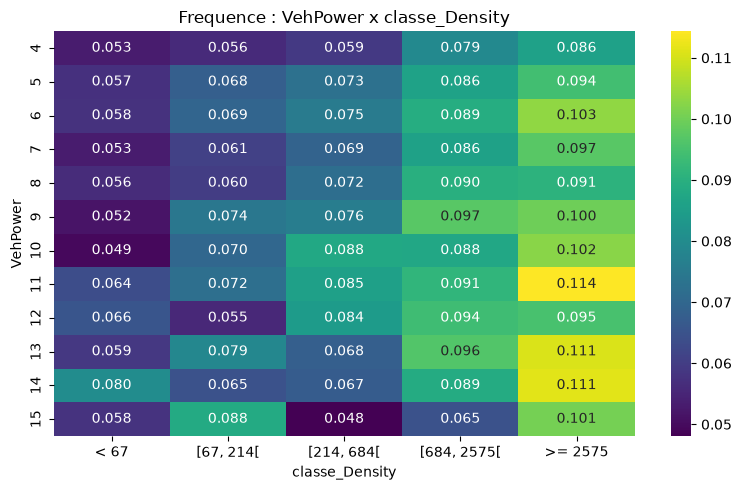

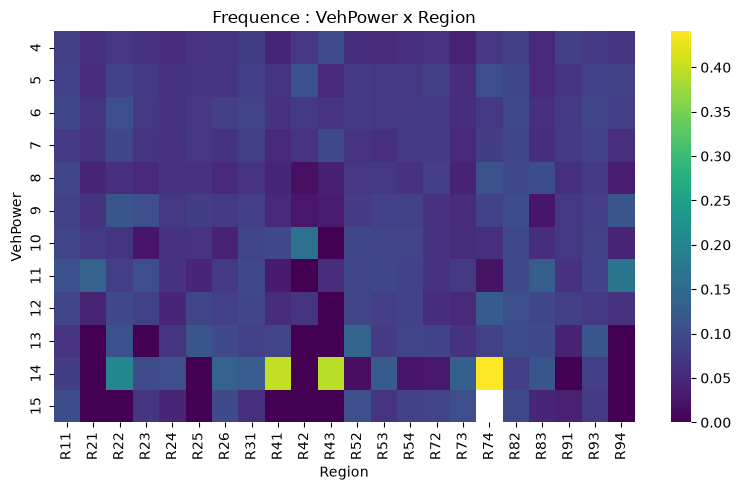

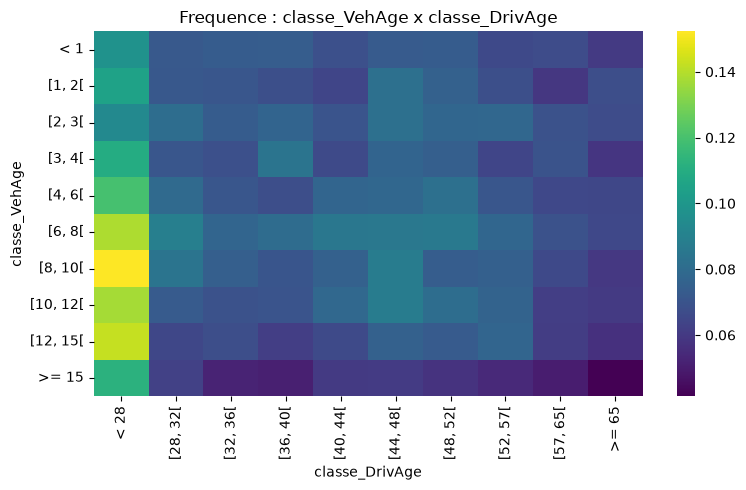

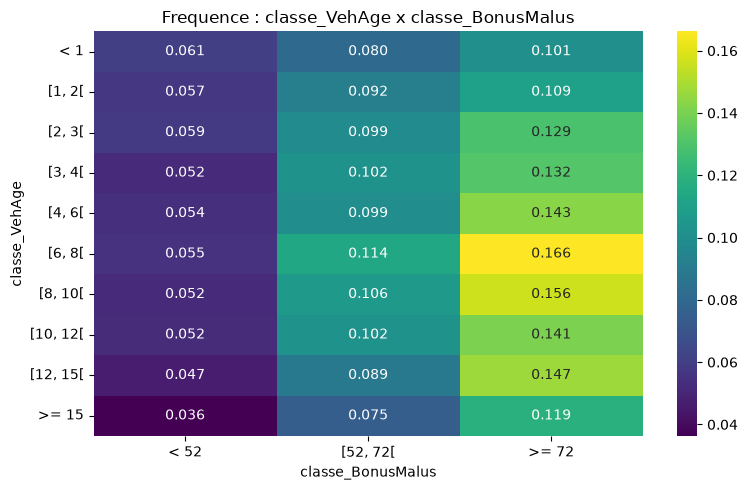

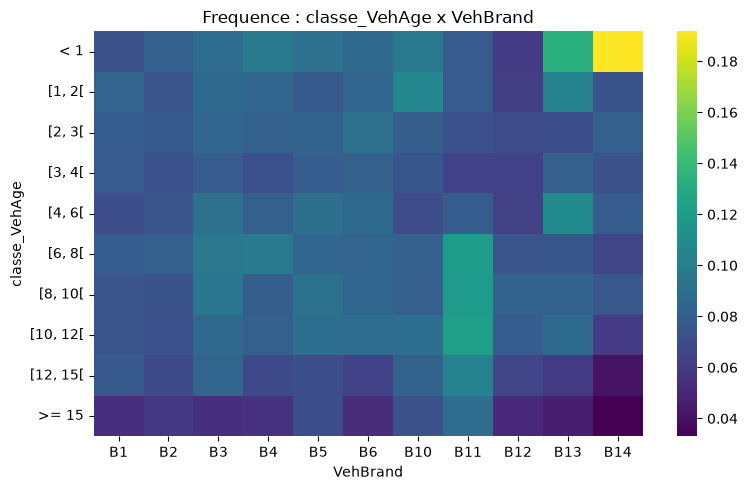

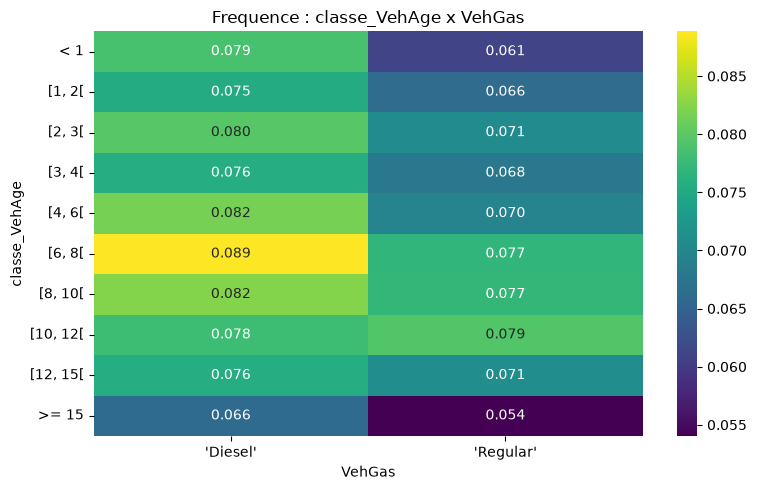

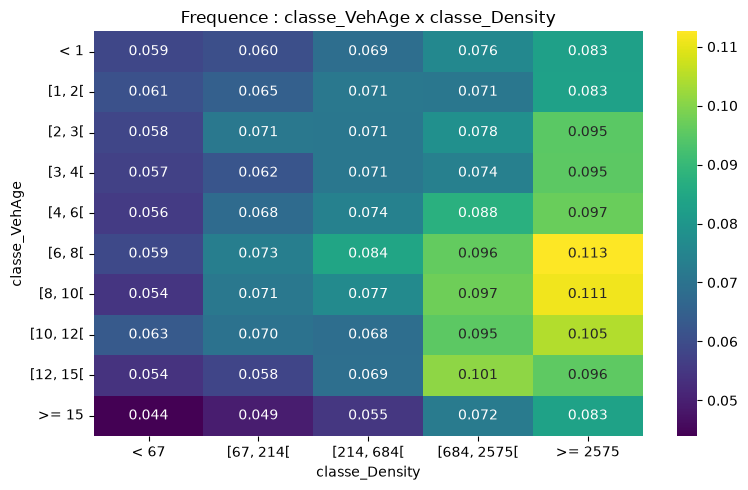

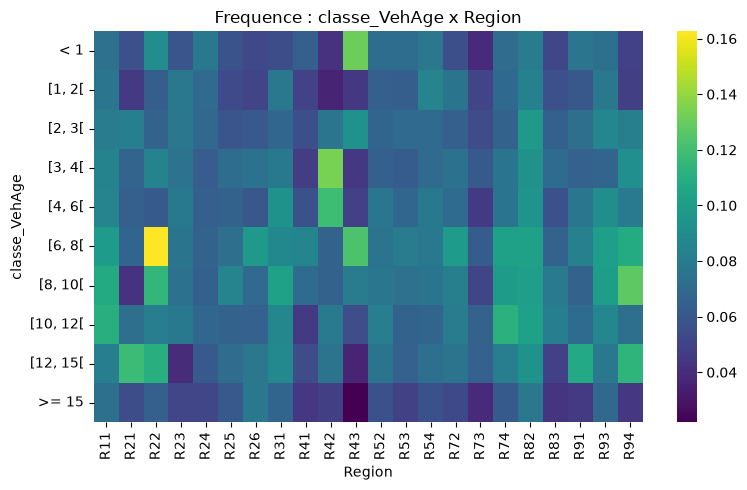

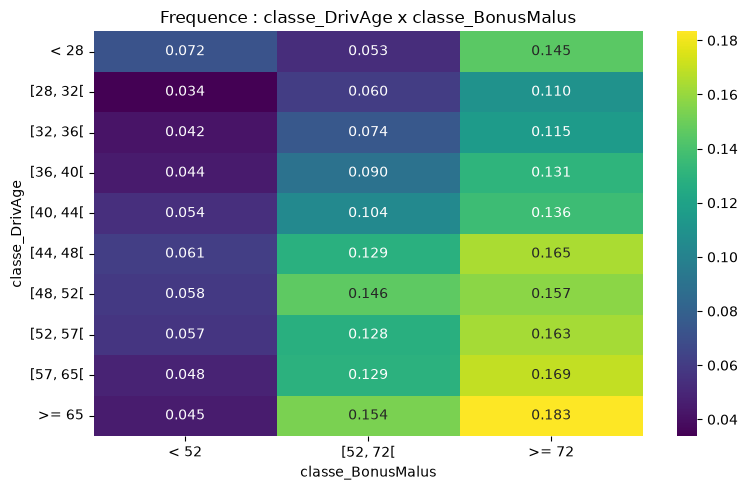

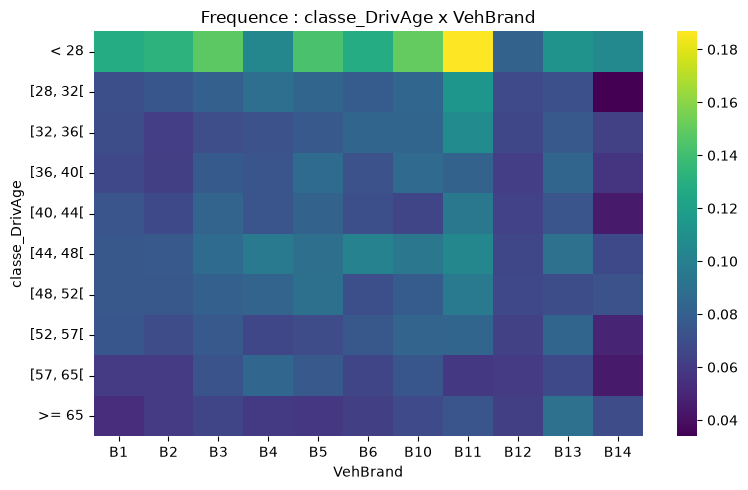

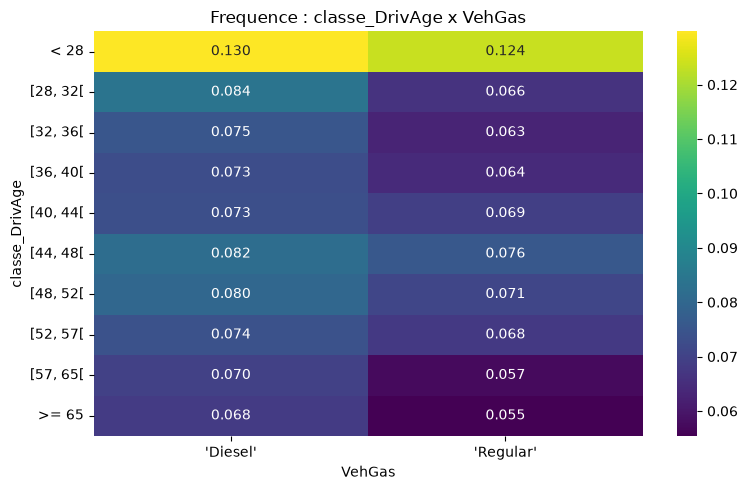

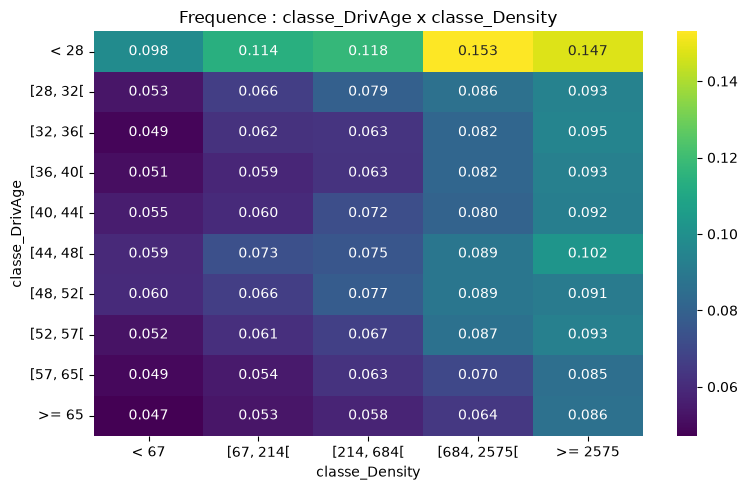

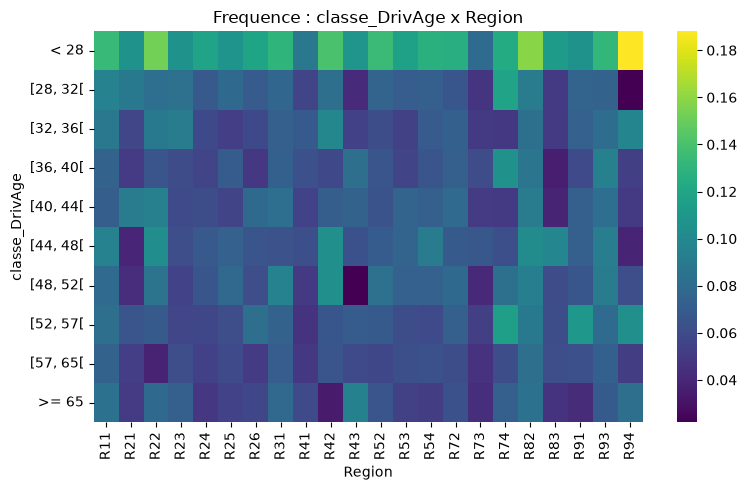

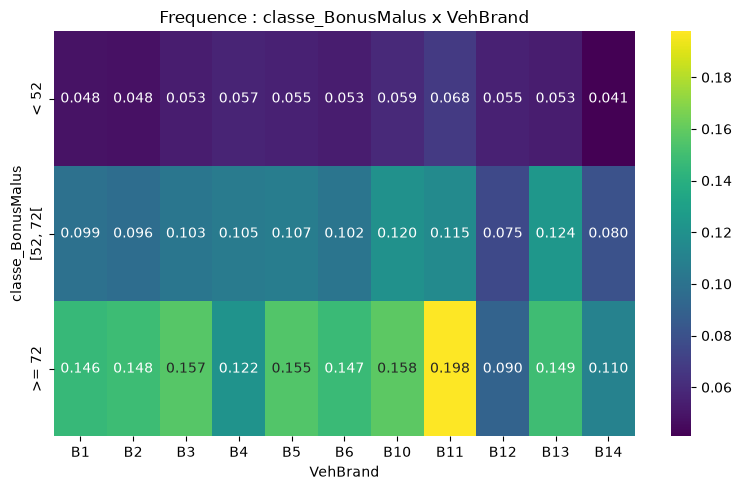

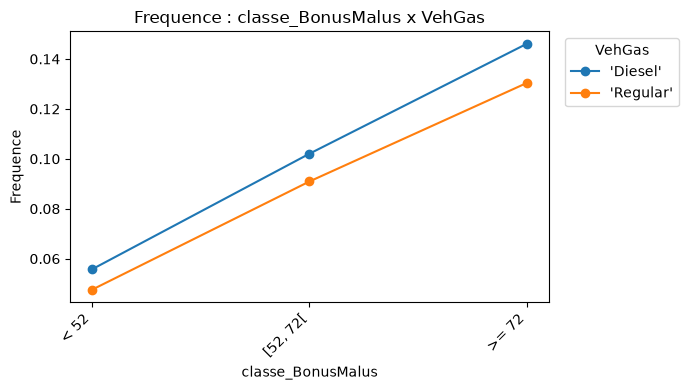

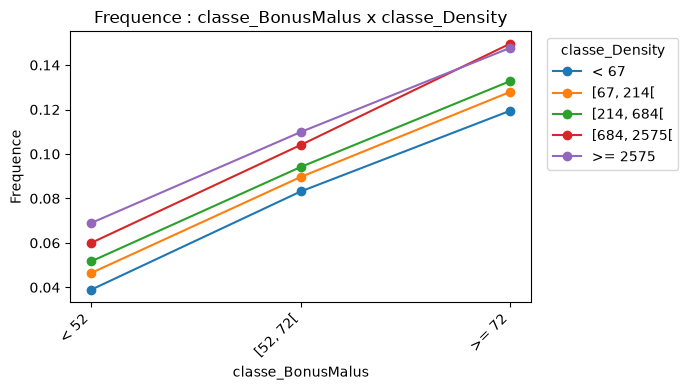

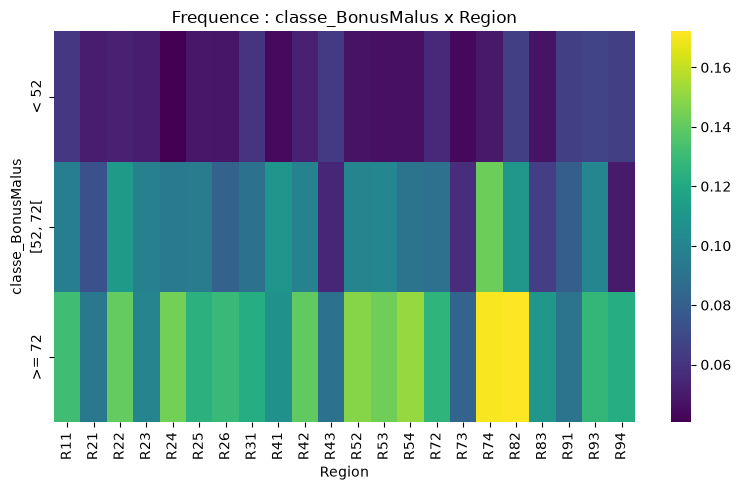

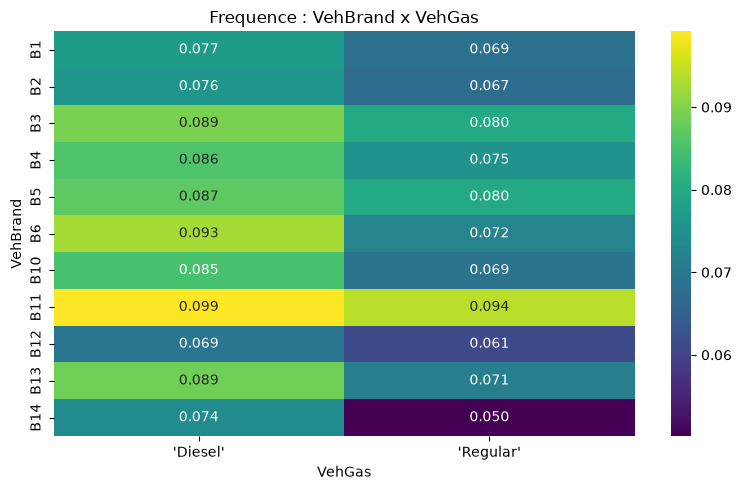

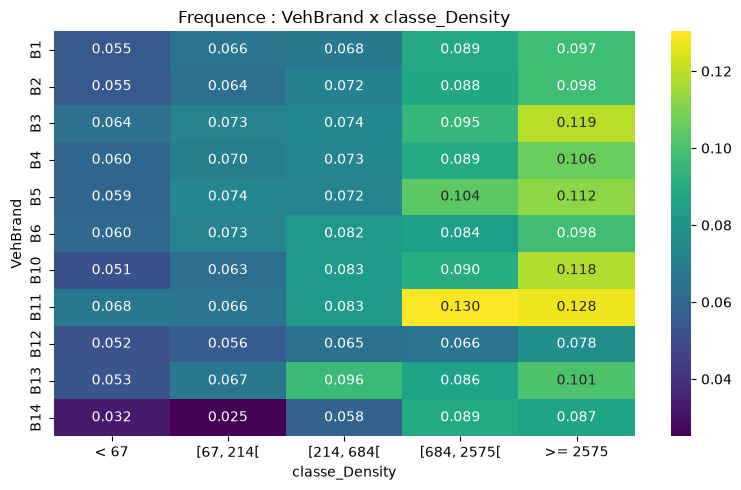

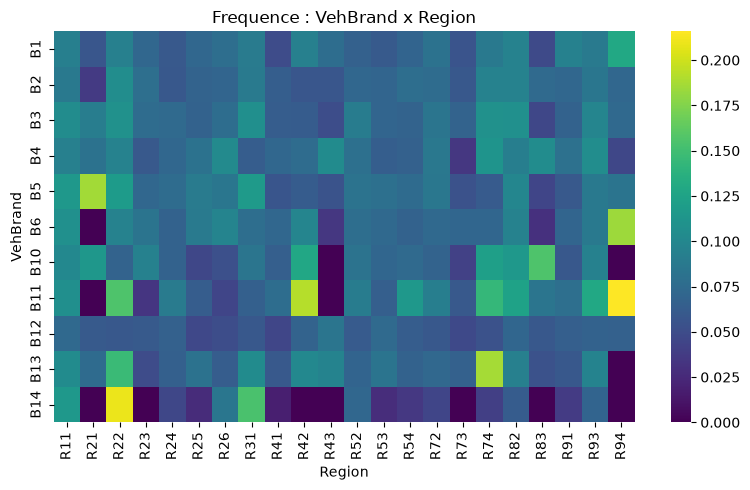

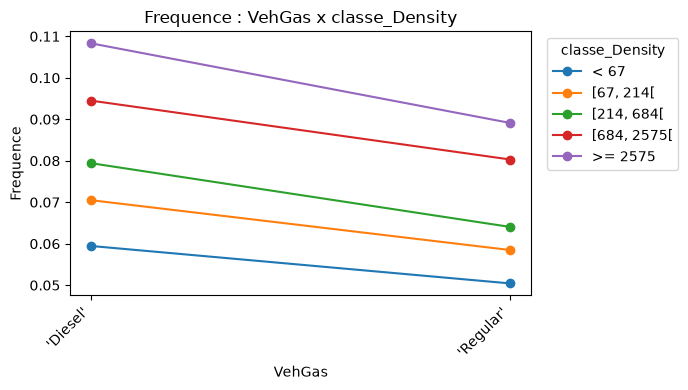

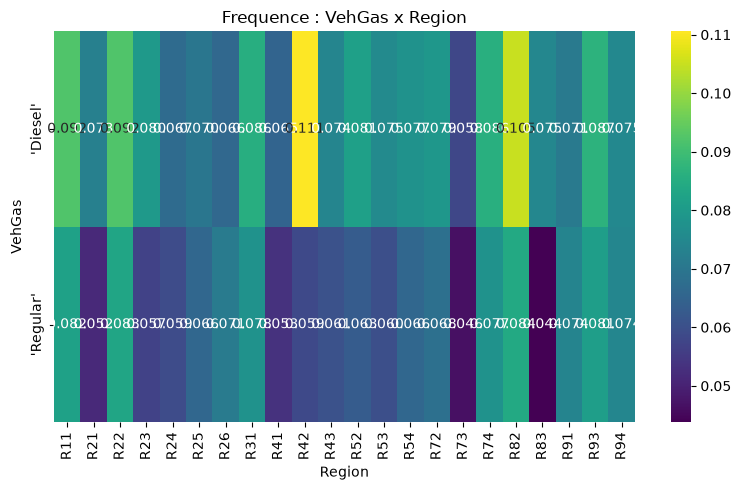

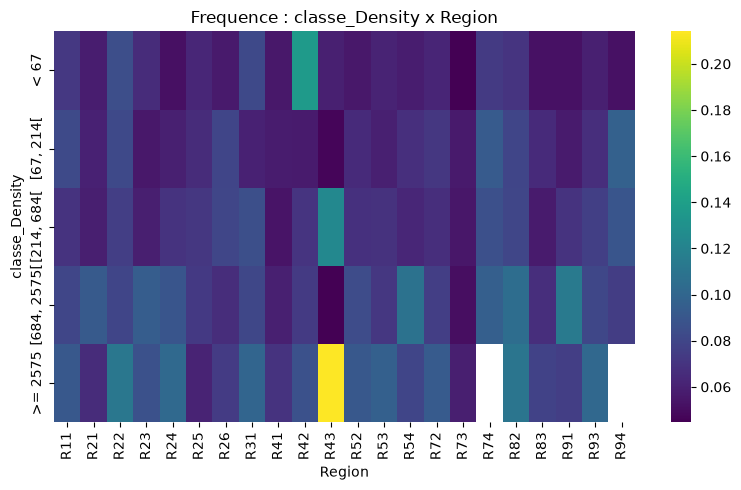

In [12]:
for var1, var2 in itertools.combinations(variables_univariees, 2):
    graphe_croise(df_analyse, var1, var2, "frequence", "Frequence", "viridis")

# E. Coût moyen croisé (mêmes combinaisons)

**Origine : Laurice**

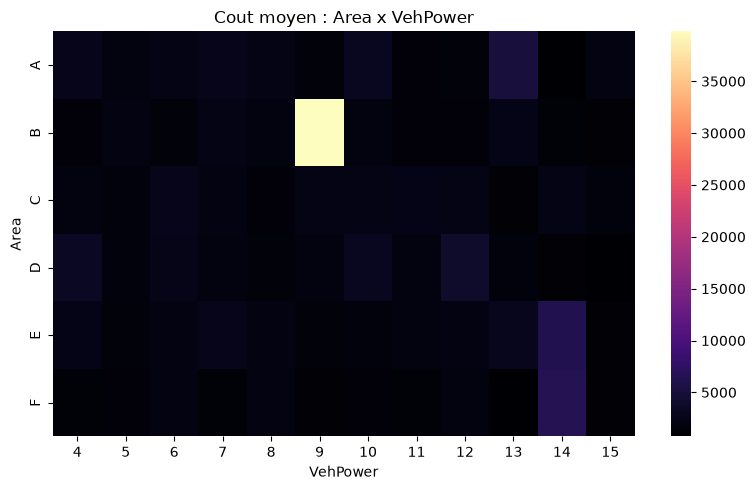

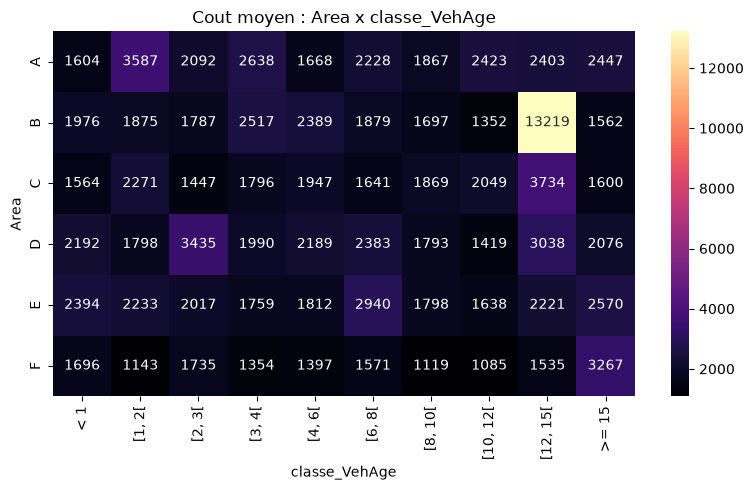

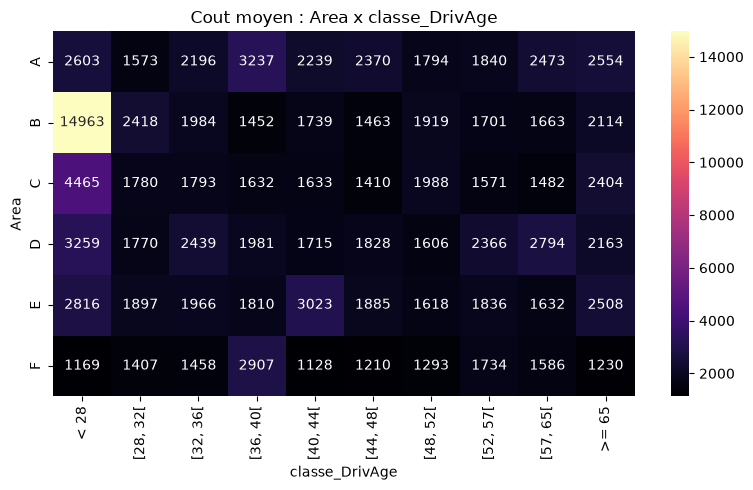

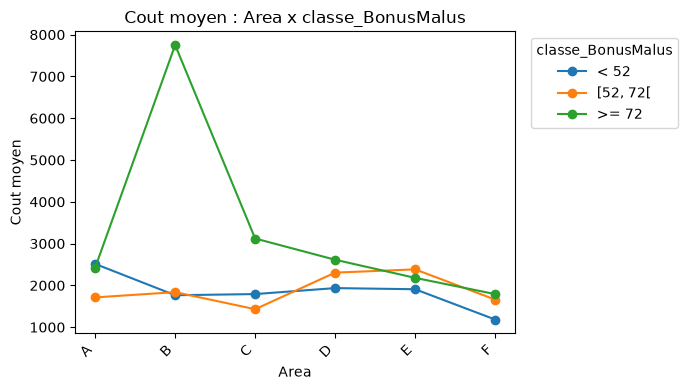

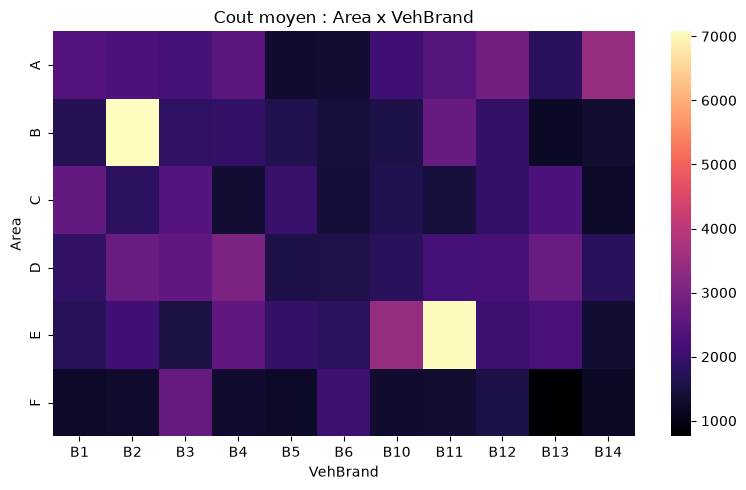

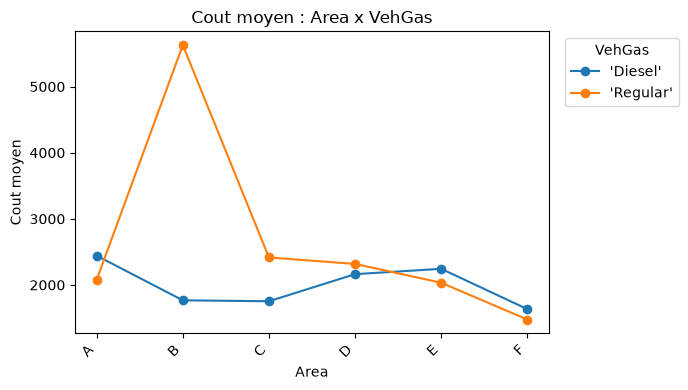

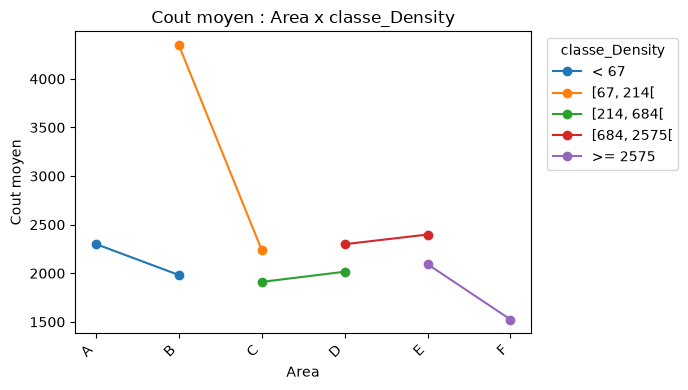

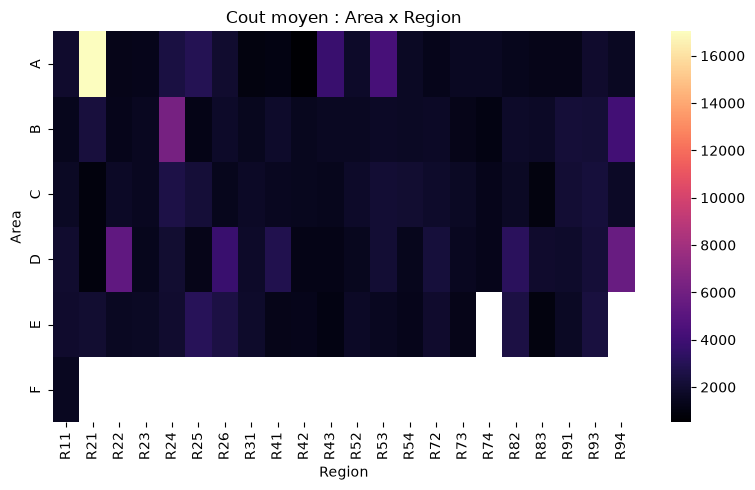

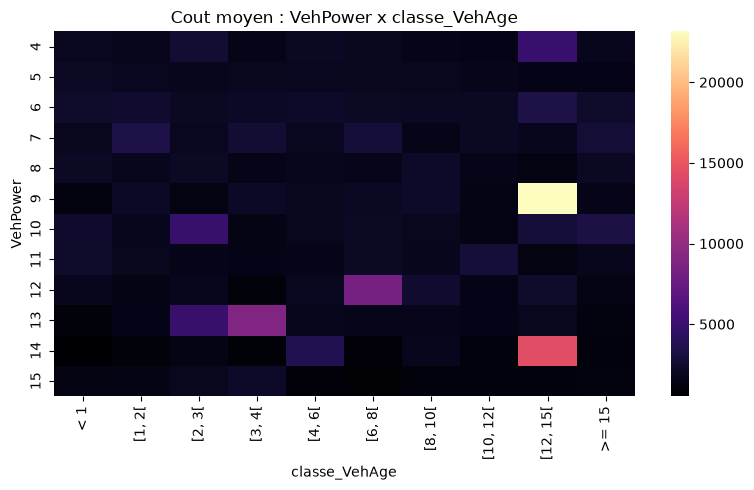

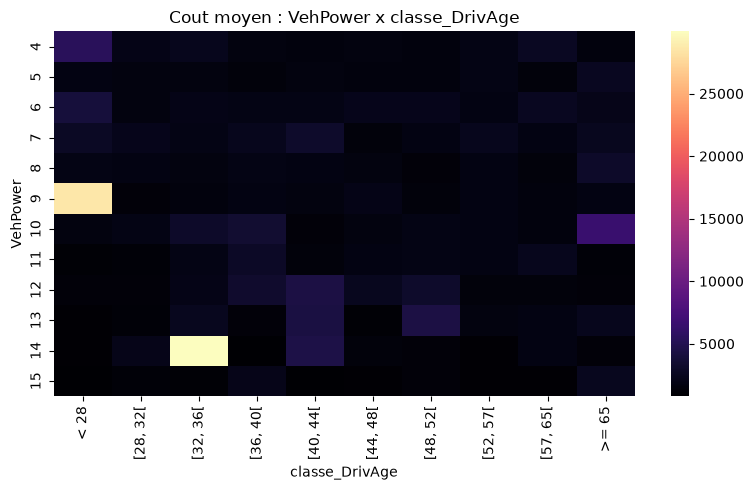

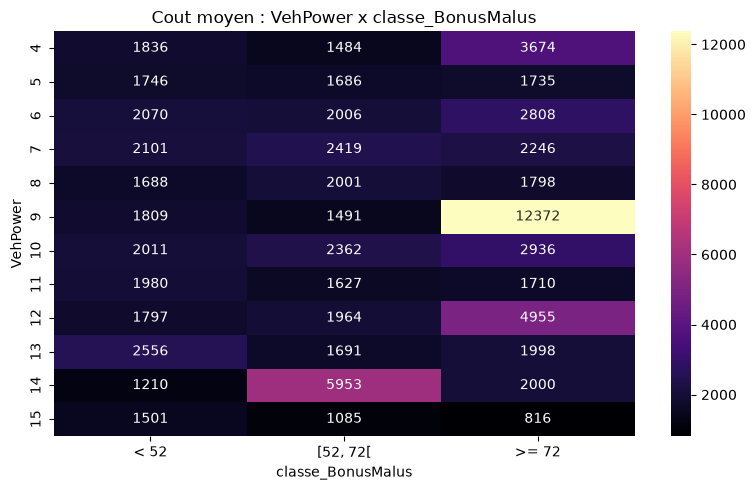

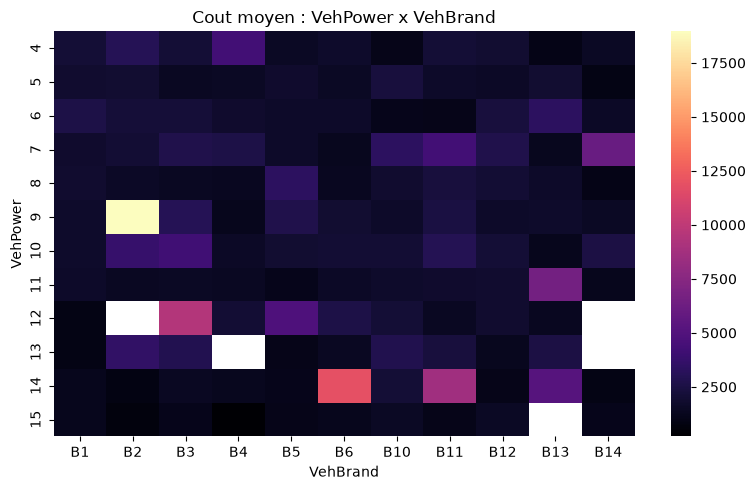

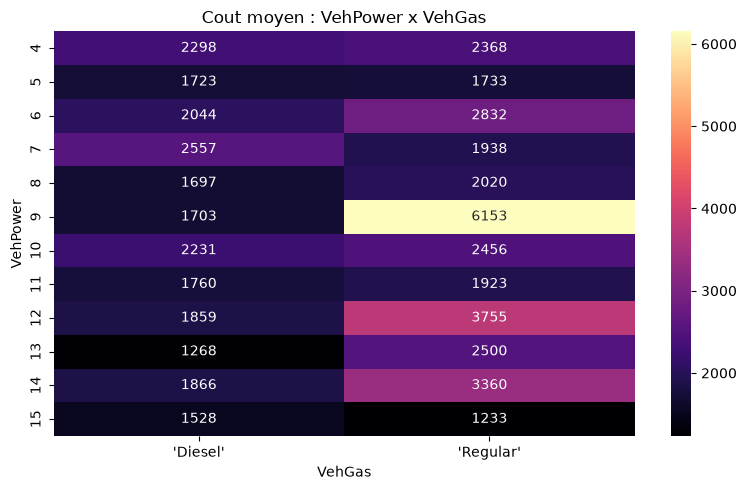

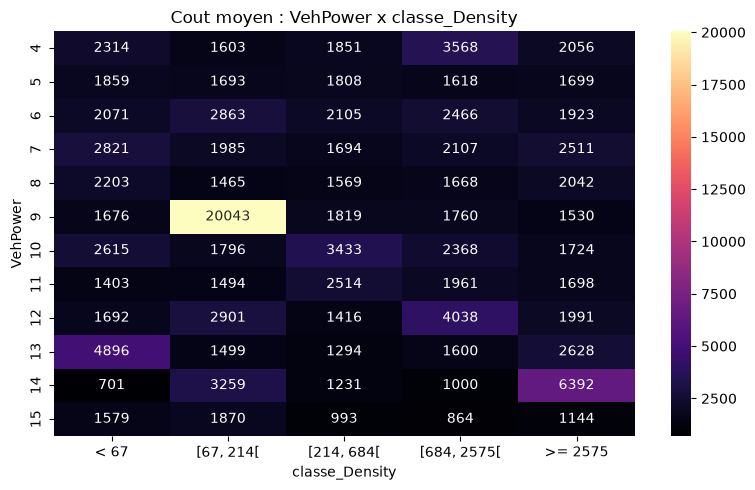

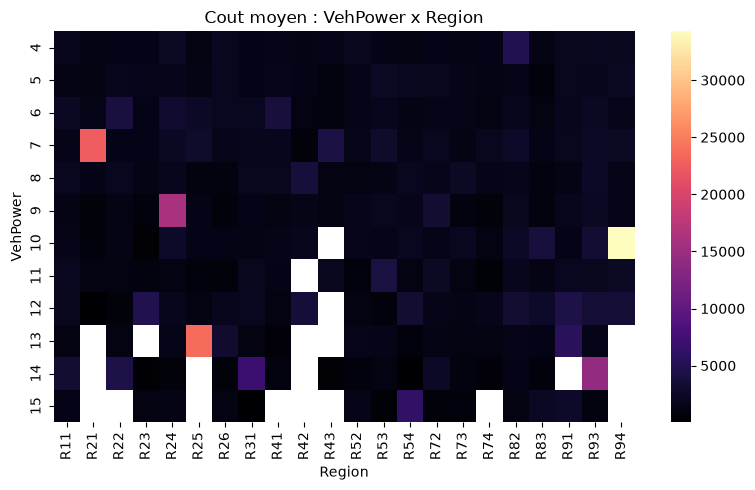

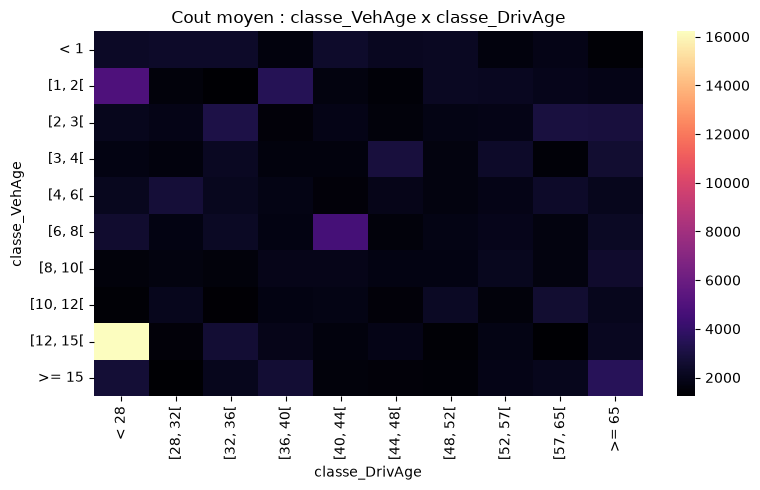

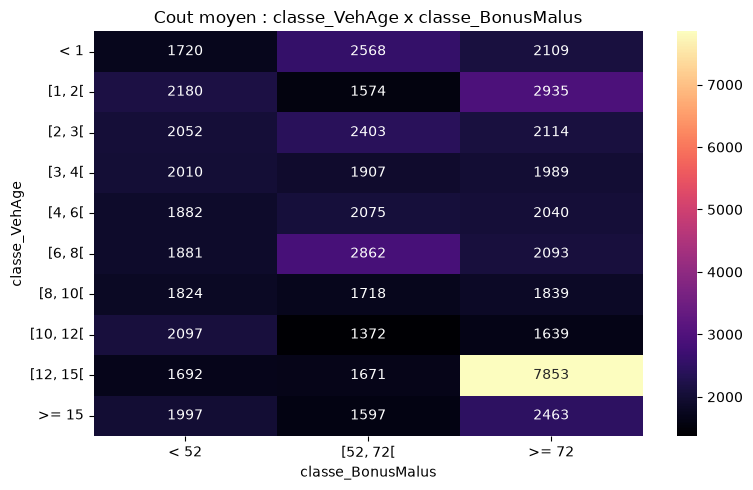

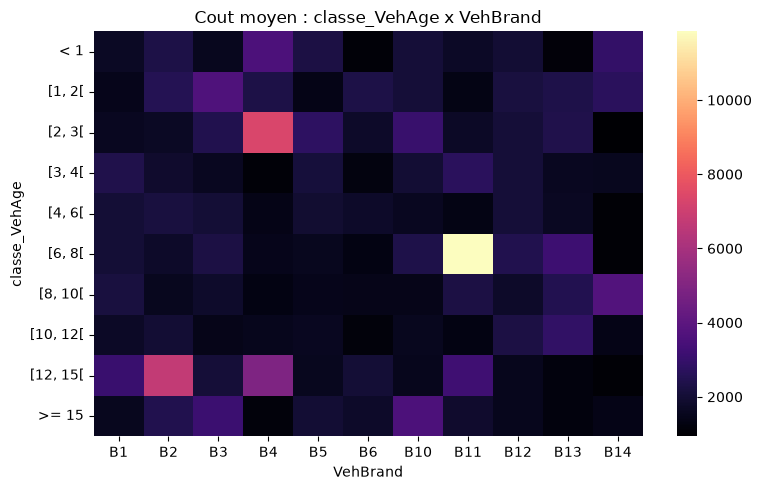

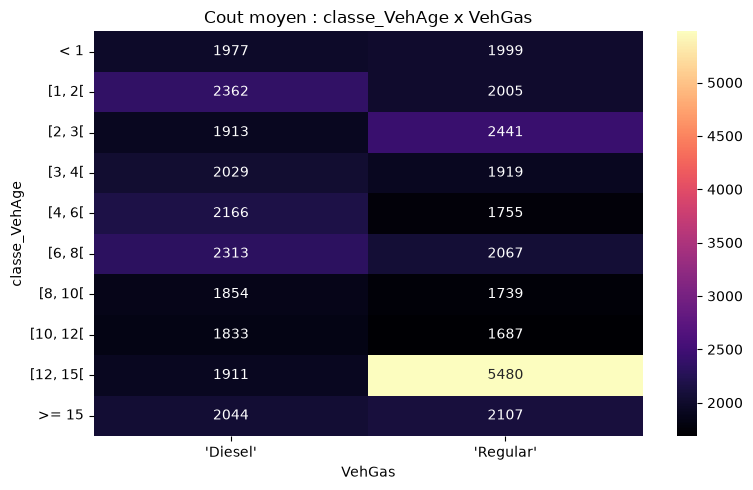

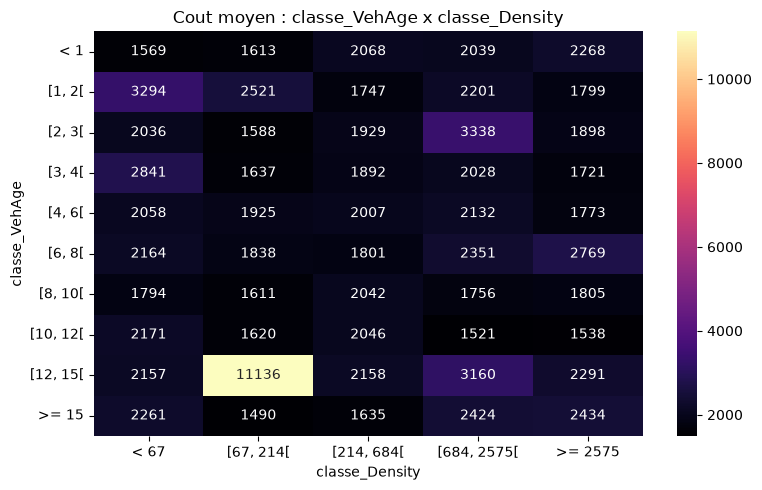

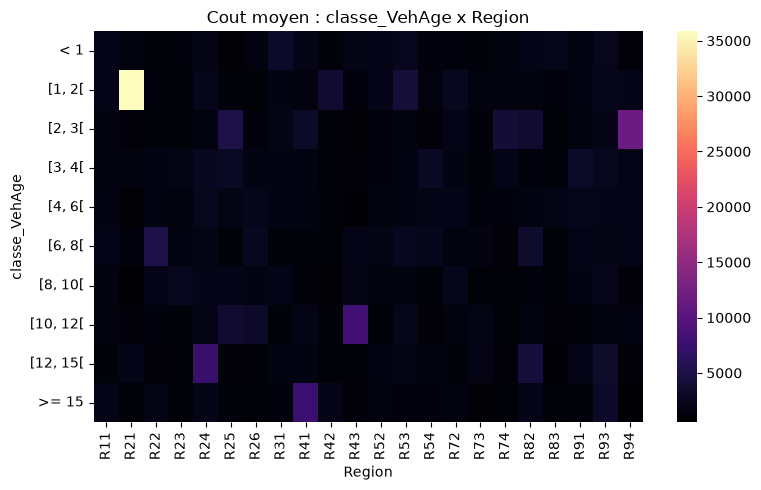

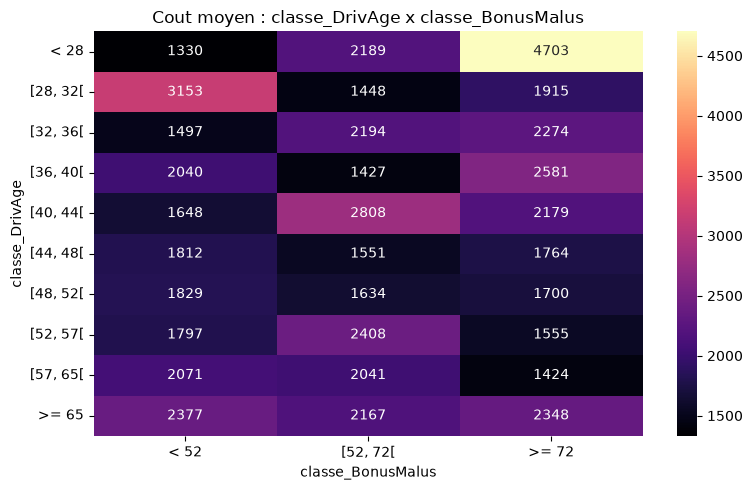

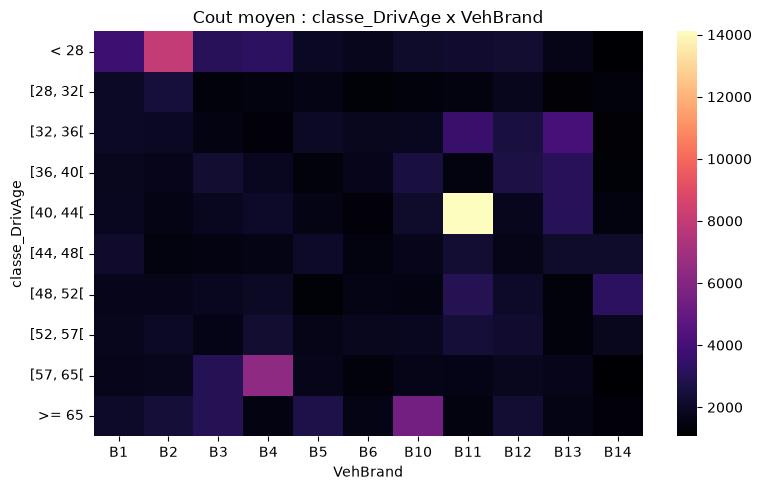

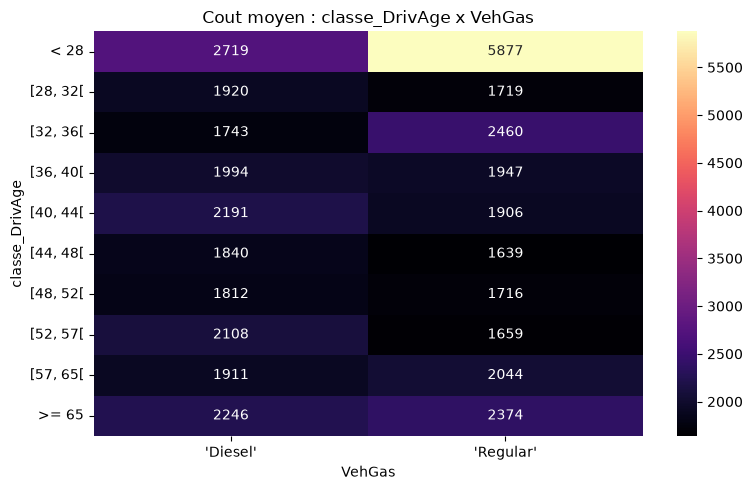

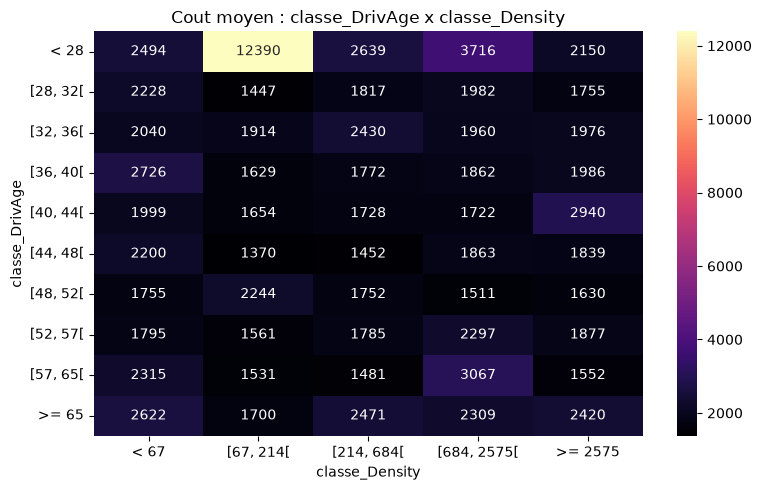

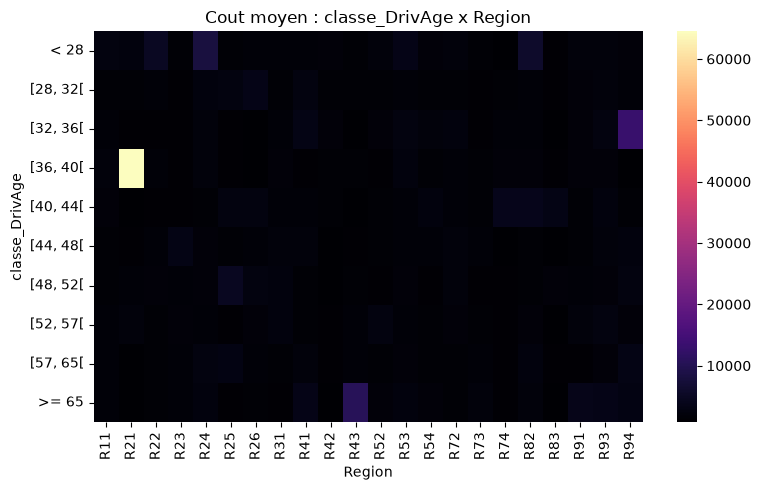

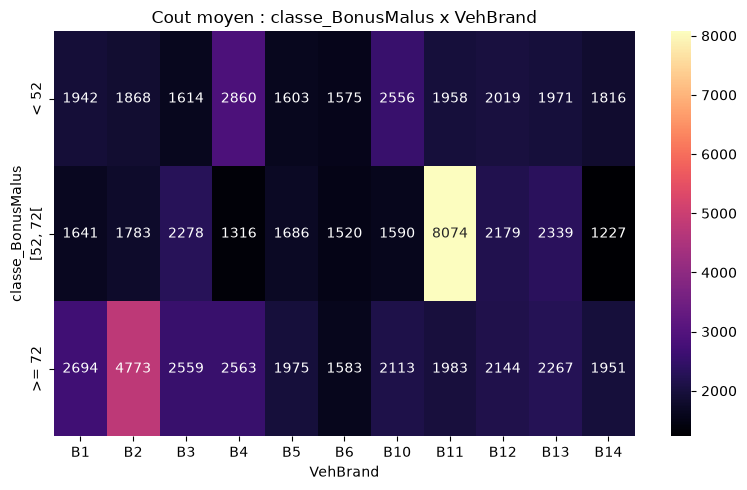

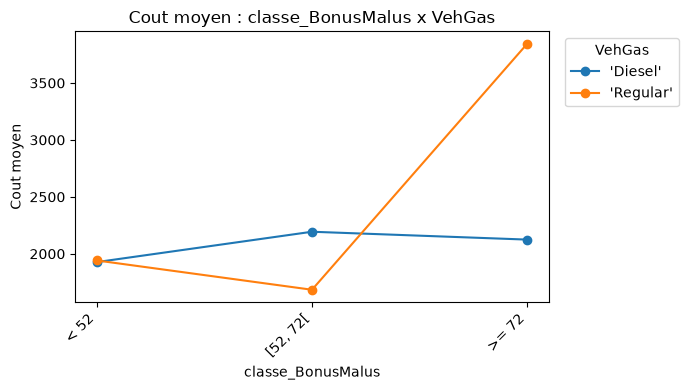

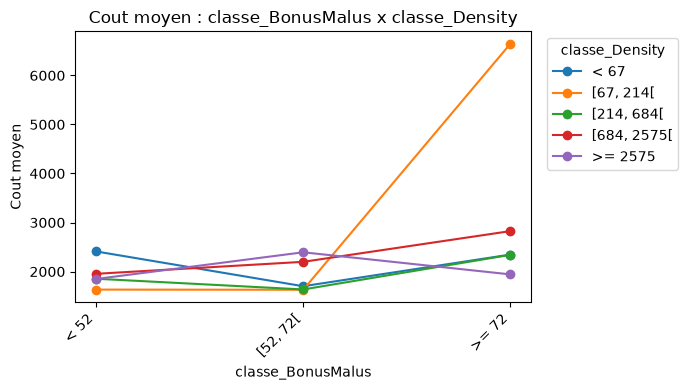

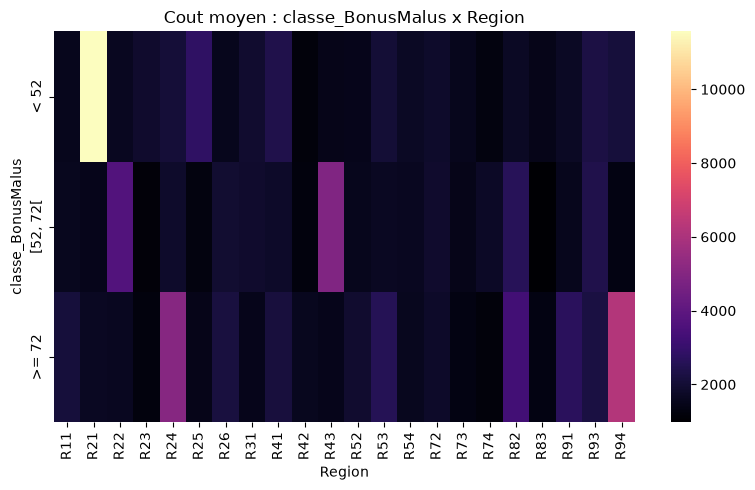

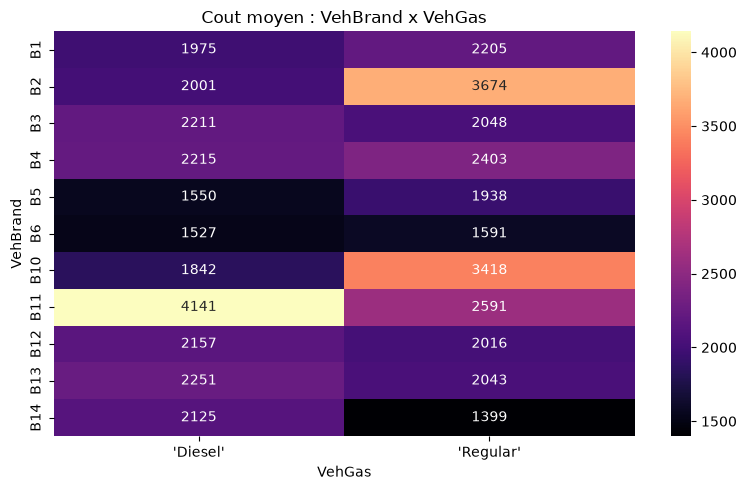

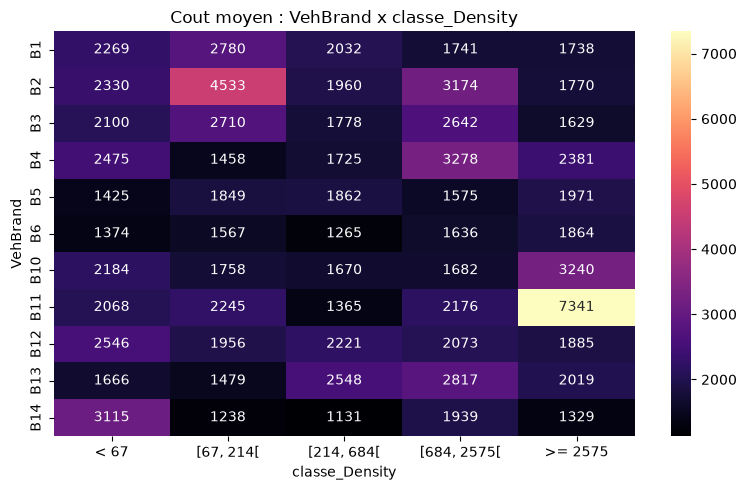

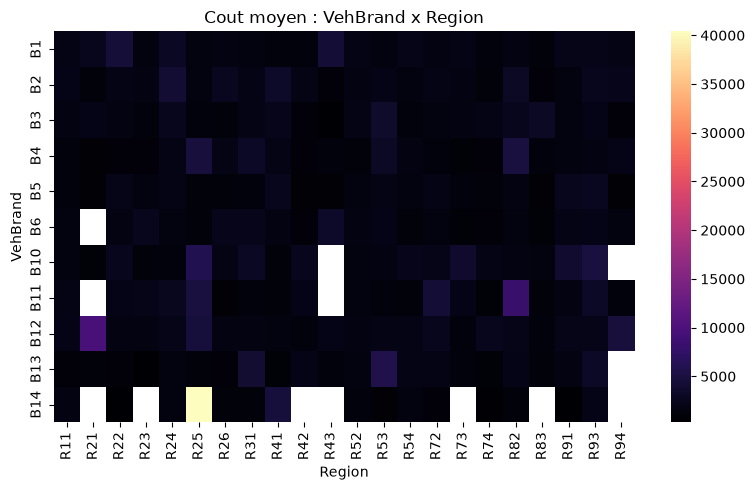

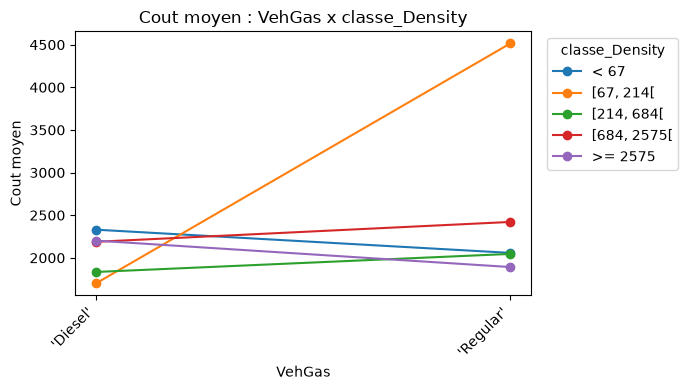

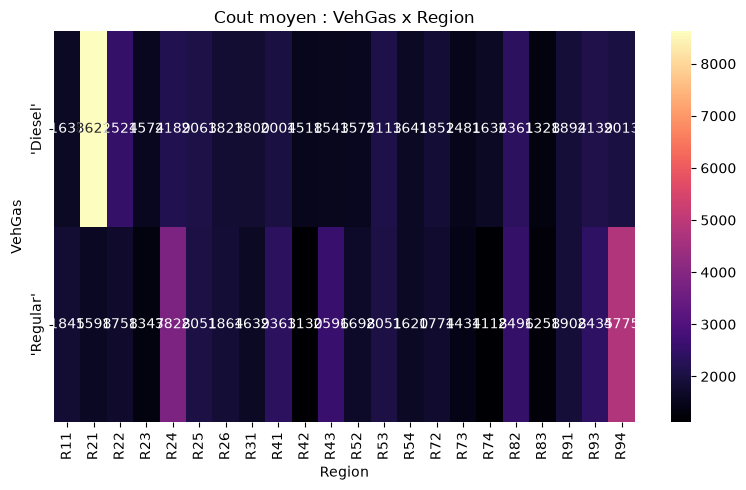

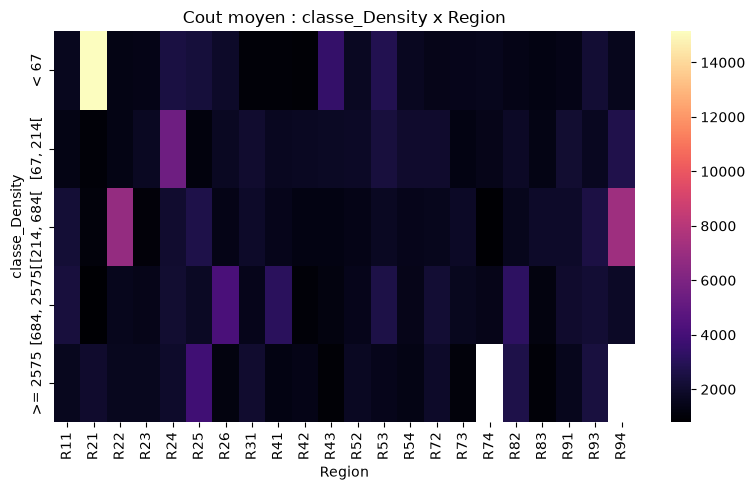

In [13]:
for var1, var2 in itertools.combinations(variables_univariees, 2):
    graphe_croise(df_analyse, var1, var2, "cout_moyen", "Cout moyen", "magma")

# F. Nombre de sinistres par Area et Region

**Origine : Laurice** — demande spécifique : comptage brut de `nb_sinistres_reel` (pas une fréquence) croisé Area x Region.

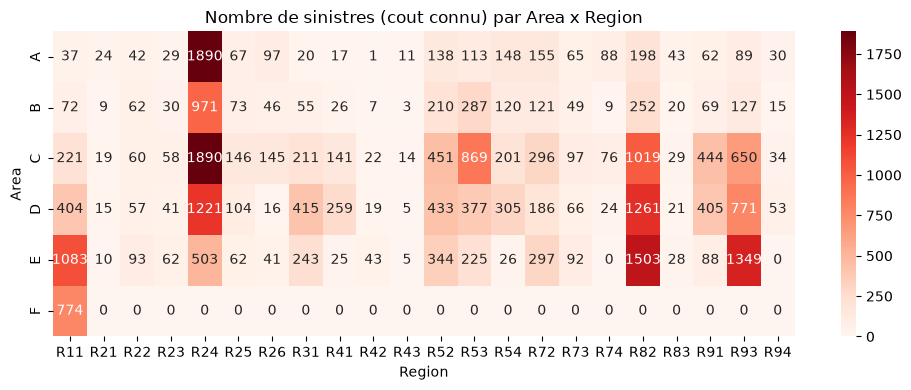

In [14]:
agrege_area_region = (
    df_analyse.groupBy("Area", "Region")
    .agg(F.sum("nb_sinistres_reel").alias("nb_sinistres_reel"))
    .toPandas()
)
pivot_area_region = agrege_area_region.pivot(index="Area", columns="Region", values="nb_sinistres_reel").fillna(0)
plt.figure(figsize=(10, 4))
sns.heatmap(pivot_area_region, annot=True, fmt=".0f", cmap="Reds")
plt.title("Nombre de sinistres (cout connu) par Area x Region")
plt.tight_layout()
plt.show()

**Origine : Laurice** — idée notée pendant la lecture des résultats Area x Region : une carte (choroplèthe) du nombre de sinistres / de la charge par région serait plus parlante qu'un tableau ou une heatmap.

**Origine : IA** — implémenté. Le dataset utilise les **anciennes régions françaises** (avant le redécoupage de 2015 : `R11`...`R94`), pas les 13 régions actuelles — il fallait donc le bon fichier de contours, pas n'importe quel GeoJSON "régions de France". Trouvé sur le dépôt public `gregoiredavid/france-geojson` (`regions-avant-redecoupage-2015.geojson`, licence ouverte Etalab), vérifié : 22 régions, correspondance exacte avec les 22 codes du dataset, 0 région orpheline. Téléchargé via `telecharger_reference_geographique()` (nouvelle fonction dans `src/telechargement.py`, même logique que pour les données OpenML : ne re-télécharge pas si le fichier existe déjà).

c:\Users\lauri\anaconda3\envs\actuary\Lib\site-packages\pyogrio\core.py:38: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


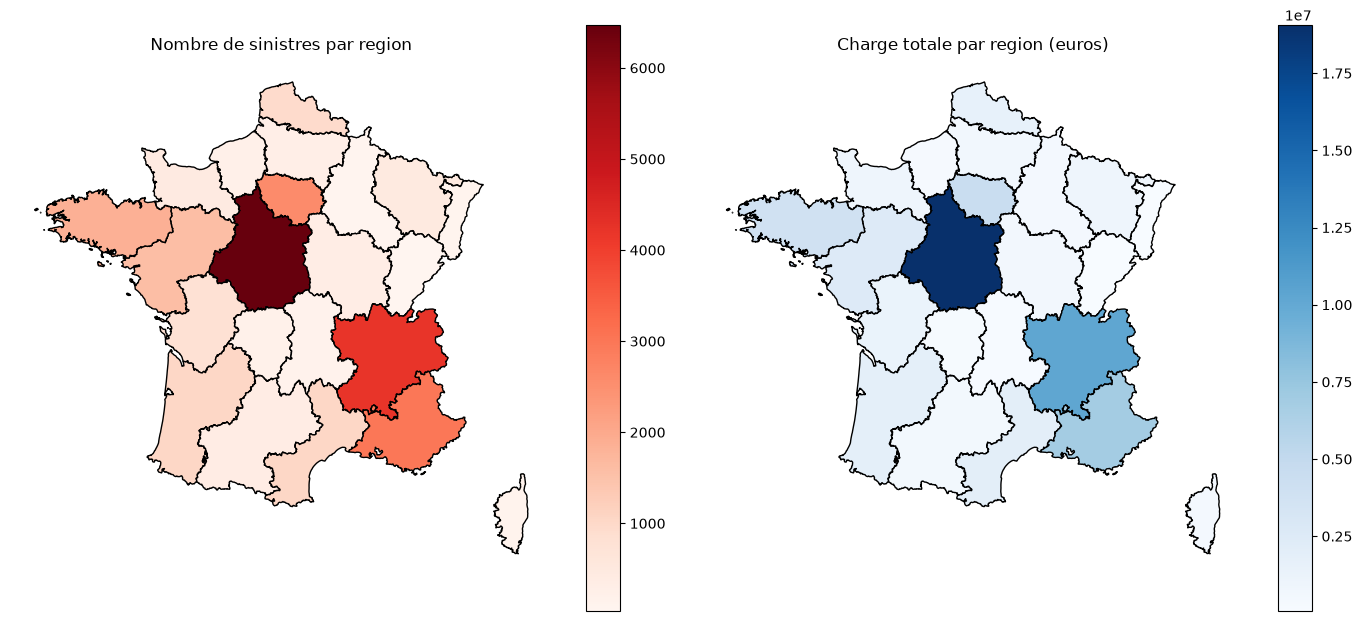

In [15]:
chemin_geojson = telecharger_reference_geographique(parametres)
regions = gpd.read_file(chemin_geojson)

agg_region_carte = agrege_area_region.groupby("Region", as_index=False).agg(
    nb_sinistres_reel=("nb_sinistres_reel", "sum")
)
# meme recalcul que pour les heatmaps, mais avec le montant en plus pour la 2e carte
agg_region_complet = (
    df_analyse.groupBy("Region")
    .agg(
        F.sum("nb_sinistres_reel").alias("nb_sinistres_reel"),
        F.sum("montant_total_sinistres").alias("montant_total_sinistres"),
    )
    .toPandas()
)
agg_region_complet["code"] = agg_region_complet["Region"].str.replace("R", "", regex=False)

fusion_regions = regions.merge(agg_region_complet, on="code", how="left")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fusion_regions.plot(column="nb_sinistres_reel", cmap="Reds", legend=True, ax=axes[0], edgecolor="black")
axes[0].set_title("Nombre de sinistres par region")
axes[0].set_axis_off()
fusion_regions.plot(column="montant_total_sinistres", cmap="Blues", legend=True, ax=axes[1], edgecolor="black")
axes[1].set_title("Charge totale par region (euros)")
axes[1].set_axis_off()
plt.tight_layout()
plt.show()

# G. Propositions complémentaires

**Origine : IA** — 2 analyses non demandées explicitement mais utiles pour décider quoi garder dans le reporting final. À valider/éliminer comme le reste.

### Prime pure par variable (fréquence x coût moyen)

**Origine : IA** — indicateur de synthèse standard en tarification : une variable peut avoir une fréquence élevée mais un coût moyen faible (ou l'inverse), la prime pure permet de comparer l'impact global en un seul chiffre, sans avoir à croiser mentalement les deux graphiques précédents.

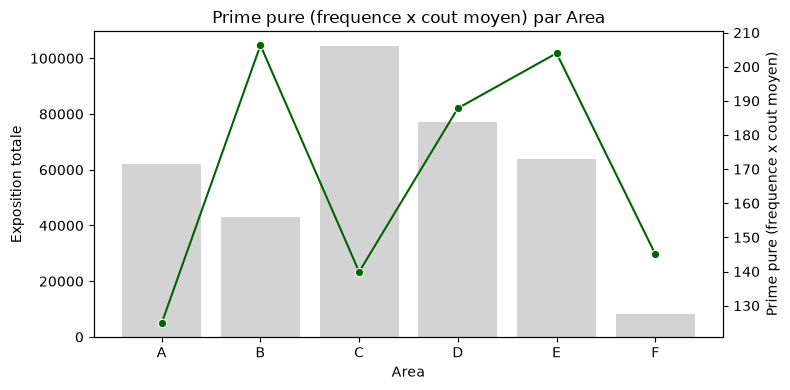

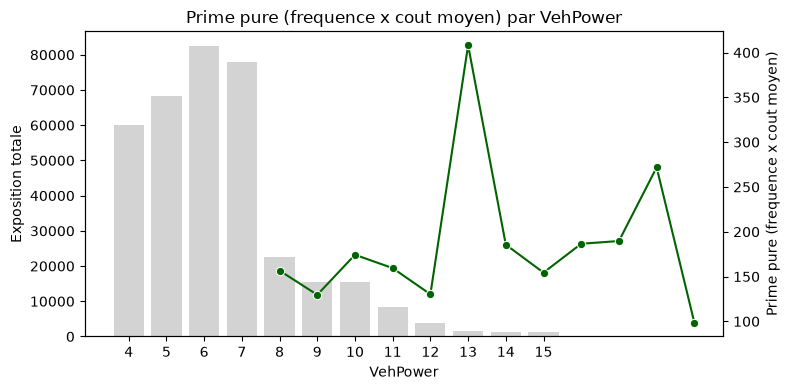

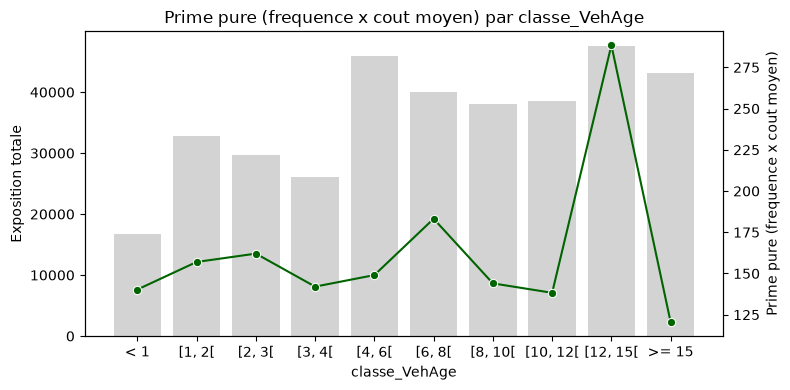

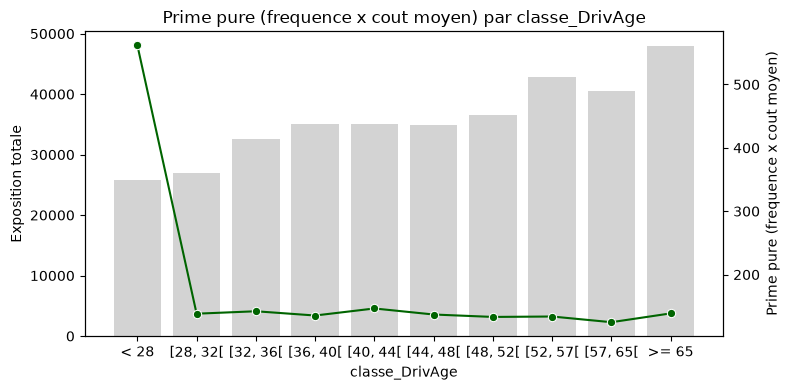

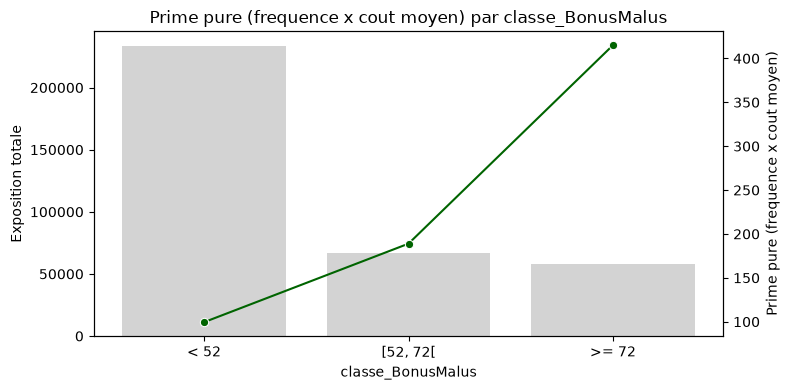

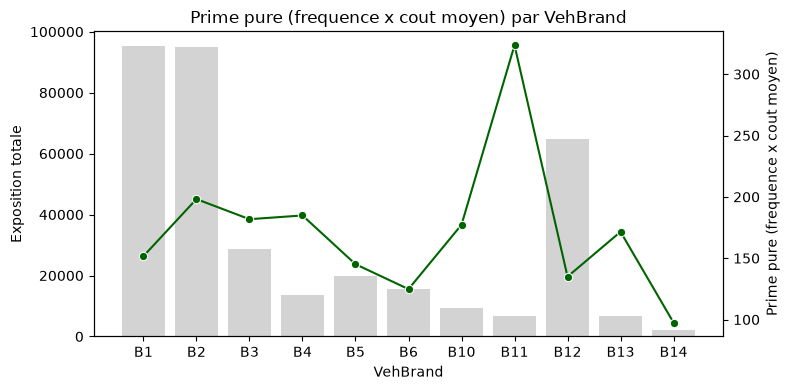

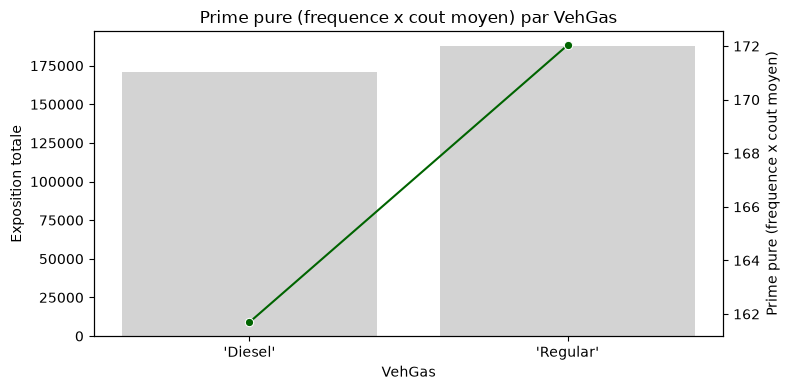

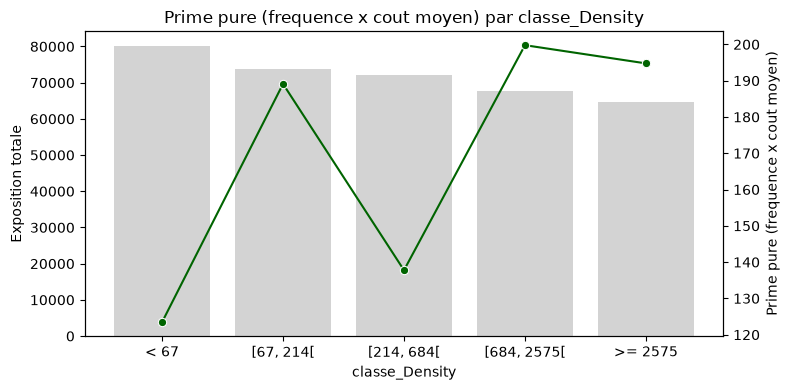

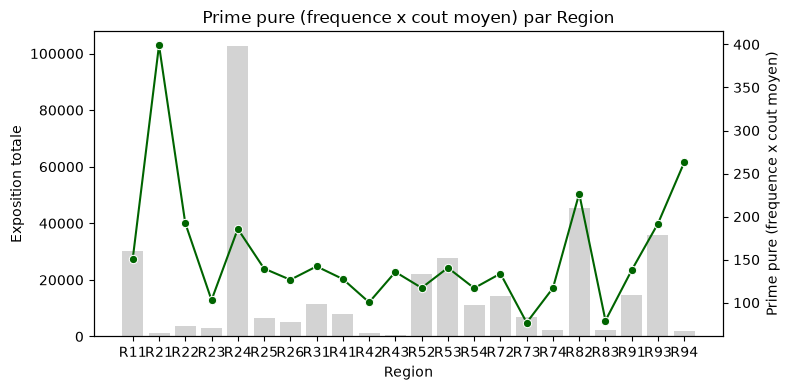

In [16]:
for variable in variables_univariees:
    tableau = tableau_univarie(df_analyse, variable).dropna(subset=["prime_pure"])
    graphe_bar_ligne(tableau, variable, "prime_pure", "Prime pure (frequence x cout moyen)", couleur="darkgreen")

### Matrice de corrélation (Spearman) entre variables continues et sinistralité

**Origine : IA** — pour prioriser quelles combinaisons croisées de la section D/E méritent le plus d'attention (celles avec la corrélation la plus forte avec `nb_sinistres_reel` ou `montant_total_sinistres`). Spearman plutôt que Pearson : capture aussi des relations non linéaires, plus adapté à des variables comme `Density` très asymétrique.

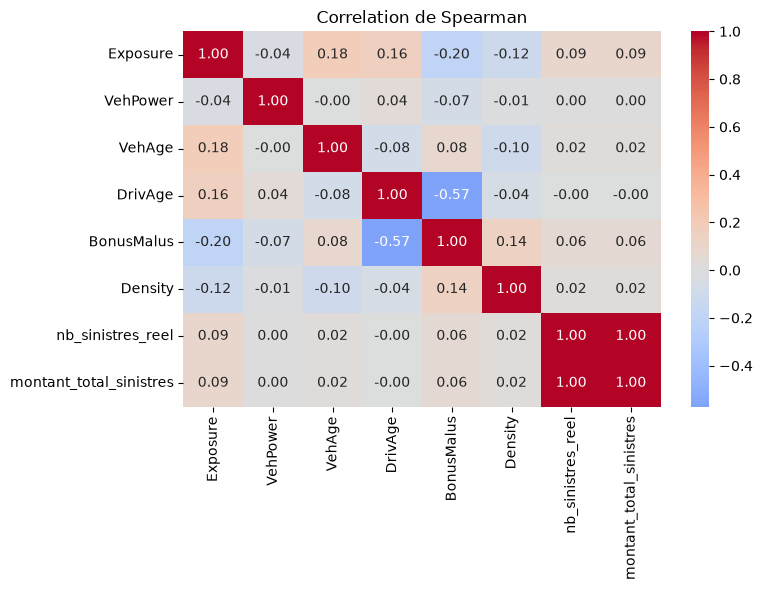

In [17]:
colonnes_numeriques = [
    "Exposure", "VehPower", "VehAge", "DrivAge", "BonusMalus", "Density",
    "nb_sinistres_reel", "montant_total_sinistres",
]
correlation = df_analyse.select(*colonnes_numeriques).toPandas().corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation de Spearman")
plt.tight_layout()
plt.show()